# 2-motor: speed-torque

Measure the bare motor's speed, current, output power and efficiency against its shaft torque at one rail, from runs started at rest at 100 % duty with the rotor's own inertia as the load, and read the rotor's inertia from the same run-ups.

## Purpose

A motor's performance curve says what it can do at a given supply. At zero torque it turns at its no-load speed, at its stall torque it stops, and in between the speed falls about linearly with the torque while the current rises. The output power is the torque times the speed, and it peaks near the middle of the curve. The efficiency is the output power over the electrical power going in, and it peaks at a fairly light load. A servo's limits and loops, from how hard a current limit cuts in to how fast a position move can go, sit somewhere on this curve, and stage 3 grades the assembled servo's curve, with its gear train, against this one.

The curve is read here with no load on the shaft but the rotor itself. The free motor is started from rest at 100 % duty, so it sweeps from stall to no load in a few tens of milliseconds. At every moment of that run-up the torque left over after the motor's own drag goes into speeding the rotor up, so the shaft torque is the rotor's inertia $J$ times the rise of the speed, $J \, \alpha$. The speed comes from the commutation ripple of the current, as in bemf-coast and no-load-current, and nothing outside the board is needed.

The same run-up reads $J$. no-load-current reads $J$ between 5.5 and 6.4 x $10^{-9}$ kg m$^2$ through the coast, once bemf-coast's reading term is out of the spin's current, every route of it through the current of a partial-duty spin. At 100 % nothing switches, so the run-up's current carries no reading term, and the drive's torque is several times the drag for the first few tens of milliseconds, so a drag that is not known well moves $J$ little. Whether the run-up agrees decides whether the rotor needs a collar of known inertia clamped on its pinion before the teardown takes the motor apart.

The run-up is also a check of every constant this stage has measured so far. The resistance, the inductance, the back-EMF constant, the drag and $J$ together draw a run-up, and the measured run-up either lands on it or shows which constant is off.

## Procedure

`capture.py` runs three cycles of a spin and a coast. A cycle is one `osc-lab sweep` with the schedule `100@300,coast:600` in both directions. It records a half second of torque-off rest, then 300 ms at 100 % duty forward from rest, then 600 ms with the bridge open while the rotor coasts to a stop, then the same pair in reverse. The spin is 300 ms because a free motor at 100 % runs at its top speed, which wears the brushes, and the run-up needs about a third of it. The coast is long enough for the rotor to stop from full speed. Twenty seconds of rest follow every cycle, the bench rule for a bare motor.

1. The bare motor in the rig, its two leads on the board's motor connector, the wrench bar off the pinion so the rotor is free. The board on the DPS, the adapter on the bus at 3 Mbps. The board runs the experiment image, so the cycles are open loop with only the raw current trip and the bus dead-man as protections.
2. `capture.py`. The DPS comes on before the board's leads go on, then the script trims the DPS until the board's own rail tap reads 5.0 V at rest, and runs the three cycles.

The level names the rail, VSYS, as in bemf-coast. The dev board has a feed diode, so the DPS sits about 0.25 V over the rail. The start draws about an amp for a few milliseconds, well under the board's overcurrent trip.

## Data

- `cycles.csv`: one row per cycle. `k` the cycle number, `volts_set` the rail level asked for, `dps_read` the DPS output that reached it, `vsys_read` the rail the board read at rest, `duty_pct` the spin duty, `repeat` 0 to 2, `t_start` and `t_end` the host time the sweep ran, `folder` the cycle's folder.
- `cycles/K/sweep.csv` and `meta.json`: the rest, the two spins and the two coasts of one cycle, one row per control tick at 20 kHz. Segment 0 is the rest, 1 the forward spin, 2 the coast chained to it, 3 and 4 the same in reverse. `duty_counts` is the applied window in timer ticks, 1200 at 100 %, and 0 from the cut on. `current_raw`, `vmotor_a`, `vmotor_b` and `vbus_raw` are ADC counts. `tick` restarts at 0 in every segment, and a jump in it is a dropped row. Each spin's stream opens with a few rows before the drive starts, and each coast's stream with a few rows of drive before the cut.
- The results of bemf-coast ($K_e$ and the ripple count), no-load-current ($K_t$, the drag under drive with the reading term out, `drive_drag_by_level_meter`, and $J$ with its routes), rest-resistance (the terminal resistance, the brush drop and its own read of these run-ups' first milliseconds) and inductance (the winding's $L$), and the stage 1 current-scale results with their absolute class and terminal-chain results for the board.

### Setup

The motor, the board and the dataset.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import butter, sosfiltfilt

from oscnb import boards, motors, results, tel
from oscnb.display import show

BLUE, ORANGE, INK, MUTED, RED = "#2a78d6", "#eb6834", "#0b0b0b", "#898781", "#d03030"   # the house colors
MOTOR = motors.MOTORS[motors.DEFAULT]                                   # the motor, with its counted parts
BOARD = boards.BOARDS[boards.DEFAULT]                                   # the board, with the parts' nominal values
CAPTURE = (Path("../../../telemetry") / f"{MOTOR.key}__{BOARD.key}" / "speed-torque" / "capture-1").resolve()
DIR_COLOR = {1: BLUE, -1: ORANGE}                                       # one color per direction, fixed through the notebook
MARK = {1: "o", -1: "^"}                                                # and the direction as the marker shape too, +1 filled, -1 open
FS = BOARD.tick_hz                                                      # rows per second, the control rate
N_R = MOTOR.ripple_per_rev                                              # commutation events per revolution, slots x brushes
print(MOTOR.key, "on", BOARD.key, "from", results.rel(CAPTURE))
print(f"{MOTOR.slots} slots x {MOTOR.brushes} brushes = {N_R} ripple events per revolution, rows at {FS} Hz")

mg90-b on dev-v006-2A-D from telemetry/mg90-b__dev-v006-2A-D/speed-torque/capture-1
3 slots x 2 brushes = 6 ripple events per revolution, rows at 20000 Hz


### cycles.csv

The three cycles, in the order they ran.

In [2]:
cycles = pd.read_csv(CAPTURE / "cycles.csv")
cycles["trim_mv"] = (cycles["vsys_read"] - cycles["volts_set"]) * 1e3   # how far the trim landed from the level
show(cycles, n=None)
print(f"{len(cycles)} cycles, {cycles['t_end'].iloc[-1] - cycles['t_start'].iloc[0]:.0f} s from the first sweep to the end of the last, "
      f"each sweep {(cycles['t_end'] - cycles['t_start']).min():.0f} to {(cycles['t_end'] - cycles['t_start']).max():.0f} s with its own rests")

,k,volts_set,dps_read,vsys_read,duty_pct,repeat,t_start,t_end,folder,trim_mv
0,0,5.000,5.250,4.993,100,0,1793219470.250,1793219522.157,cycles/0,-7.000
1,1,5.000,5.250,4.993,100,1,1793219542.162,1793219593.044,cycles/1,-7.000
2,2,5.000,5.250,4.993,100,2,1793219613.049,1793219664.811,cycles/2,-7.000


3 cycles, 195 s from the first sweep to the end of the last, each sweep 51 to 52 s with its own rests


Three cycles about 70 s apart, the rail trimmed once to 4.993 V at rest, 7 mV under the level. The run-ups below read the terminal volts row by row, so the level's trim enters nothing.

### The results carried in

The stage 1 conversions, and every constant this notebook reads from the earlier stage 2 notebooks. `drag_curve` turns no-load-current's fit of the settled spin's current against speed, with bemf-coast's reading term taken out, into a function. The run-ups at 100 % carry no reading term, so the curve with the term in, `drive_drag_by_level`, would take that term off them as if it were drag. That fit is a constant plus a term in the log of the speed, good over the speeds it was fitted on, and its log runs away below them, so the current is held at its value at the lowest speed there.

In [3]:
CS = results.read("1-board", "current-scale", pair=BOARD.key)         # counts per amp and the in-drive offset, graded at 100 % duty
TC = results.read("1-board", "terminal-chain", pair=BOARD.key)        # counts per volt of tap difference, the rail tap
BC = results.read("2-motor", "bemf-coast", pair=MOTOR.key)            # Ke, its trend with speed, the ripple count
NL = results.read("2-motor", "no-load-current", pair=MOTOR.key)       # Kt, the drag under drive with the reading term out, J and its routes
RR = results.read("2-motor", "rest-resistance", pair=MOTOR.key)       # the terminal resistance, the brush drop, the earlier read of these run-ups
IND = results.read("2-motor", "inductance", pair=MOTOR.key)           # the winding's inductance and time constant
A_PER_COUNT = 1 / CS["counts_per_a"]["value"]                          # amps per count over the zero
I_DRIVE_OFFSET = CS["drive_offset_counts"]["value"]                   # counts the chain reads over its rest zero with the bridge driving
I_CLASS_PCT = CS["counts_per_a_class_pct"]["value"]                  # % of the reading, current-scale's absolute class on its counts per amp
V_PER_COUNT = 1 / TC["terminal_counts_per_v"]["value"]                 # volts of terminal difference per count
T_OFFSET = TC["terminal_offset_counts"]["value"]                      # counts the difference reads over the truth under DC current
rail_v = lambda n: (np.asarray(n, float) - TC["rail_offset_counts"]["value"]) / TC["rail_counts_per_v"]["value"]
KE = BC["ke_v_s_per_rad"]["value"]                                    # V s/rad, the coast route
KT = NL["kt_n_m_per_a"]["value"]                                      # N m/A, the same number in SI units
L_H = IND["l_mh"]["value"] * 1e-3                                     # the winding's inductance in henries
J_GUESS = NL["j_kg_m2"]["value"]                                      # no-load-current's working J, for the pictures before this notebook reads its own
assert int(BC["ripple_per_rev"]["value"]) == N_R                      # the count bemf-coast read Ke with is the one used here

def drag_curve(level):
    # the no-load current of a settled spin at one rail as a function of speed in rad/s, from no-load-current, with bemf-coast's
    # reading term taken out, since a 100 % run-up carries none. The curve is a constant plus a term in the log of the speed,
    # fitted over the speeds that rail reached. Under its lowest speed the log runs to minus infinity, so the current is held
    # at the curve's value there.
    c = NL["drive_drag_by_level_meter"][level]
    a, b, lo = c["a_a"]["value"], c["b_a"]["value"], c["speed_range_rev_s"]["lo"]
    return lambda w: a + b * np.log(np.maximum(np.asarray(w, float), 2 * np.pi * lo) / (2 * np.pi * 100))

I0 = drag_curve("5 V")                                                # the drag under drive at this rail, as a current
I0_HI = drag_curve("7.4 V")                                           # the 7.4 V curve, fitted up to 510 rev/s, for the bracket
D5 = NL["drive_drag_by_level_meter"]["5 V"]["speed_range_rev_s"]
D7 = NL["drive_drag_by_level_meter"]["7.4 V"]["speed_range_rev_s"]
print(f"current {CS['counts_per_a']['value']:.1f} counts/A, in-drive offset {I_DRIVE_OFFSET:+.1f} counts, graded on DC at 100 % over "
      f"{CS['amps_range']['lo']:.2f} to {CS['amps_range']['hi']:.2f} A, absolute class {I_CLASS_PCT:.0f} % of the reading")
print(f"terminal difference {TC['terminal_counts_per_v']['value']:.2f} counts/V with {T_OFFSET:+.1f} counts under DC current")
print(f"Ke = Kt = {KE * 1e3:.4f} mV s/rad ({BC['ke_v_s_per_rad']['lo'] * 1e3:.4f} to {BC['ke_v_s_per_rad']['hi'] * 1e3:.4f}), read up to "
      f"{BC['speed_range_rev_s']['hi']:.0f} rev/s")
print(f"L {IND['l_mh']['value']:.3f} mH, tau {IND['tau_us']['value']:.0f} us from inductance")
print(f"drag under drive at 5.0 V, the reading term out: {D5['lo']:.0f} to {D5['hi']:.0f} rev/s fitted, {I0(2 * np.pi * 100) * 1e3:.1f} mA at 100 rev/s and "
      f"{I0(2 * np.pi * D5['hi']) * 1e3:.1f} mA at {D5['hi']:.0f} rev/s; the 7.4 V curve, fitted from {D7['lo']:.0f} to {D7['hi']:.0f} rev/s, sits "
      + ", ".join(f"{(I0_HI(2 * np.pi * x) - I0(2 * np.pi * x)) * 1e3:+.1f}" for x in (150, 338, 540)) + " mA from it at 150, 338 and 540 rev/s")
print(f"J from no-load-current {NL['j_kg_m2']['value'] * 1e9:.2f} x 1e-9 kg m^2, bracket {NL['j_kg_m2']['lo'] * 1e9:.2f} to {NL['j_kg_m2']['hi'] * 1e9:.2f}")
print(f"rest-resistance: r_term {RR['r_term_median_ohm']['value']:.3f} ohm at {RR['r_term_amps']['value']:.2f} A, brush drop "
      f"{RR['v0_brush_v']['value']:+.2f} V ({RR['v0_brush_v']['lo']:.1f} to {RR['v0_brush_v']['hi']:.1f}), and from these run-ups "
      f"r_runup {RR['r_runup_ohm']['value']:.3f} ohm and j_runup {RR['j_runup_kg_m2']['value'] * 1e9:.2f} x 1e-9 kg m^2")

current 1135.0 counts/A, in-drive offset +5.3 counts, graded on DC at 100 % over 0.23 to 1.31 A, absolute class 2 % of the reading
terminal difference 248.37 counts/V with +2.4 counts under DC current
Ke = Kt = 1.1684 mV s/rad (1.1605 to 1.1725), read up to 491 rev/s
L 0.833 mH, tau 194 us from inductance
drag under drive at 5.0 V, the reading term out: 64 to 338 rev/s fitted, 53.1 mA at 100 rev/s and 79.3 mA at 338 rev/s; the 7.4 V curve, fitted from 105 to 510 rev/s, sits -1.4, +2.2, +4.3 mA from it at 150, 338 and 540 rev/s
J from no-load-current 6.30 x 1e-9 kg m^2, bracket 5.47 to 6.43
rest-resistance: r_term 4.455 ohm at 0.78 A, brush drop +0.06 V (0.0 to 0.5), and from these run-ups r_runup 4.182 ohm and j_runup 5.90 x 1e-9 kg m^2


Two of these need a word before they are used. The current-scale grade is DC at 100 % duty, the same bridge state as these run-ups, so its in-drive offset applies here as measured, from 0.23 to 1.31 A. The settled end of a run-up sits at about 0.11 A, under that range, where the offset of 5.3 counts is 5 % of the reading. And the drag curve at 5.0 V was fitted from 64 to 338 rev/s, while the run-ups here reach about 550 rev/s, so above 338 rev/s the curve is extrapolated. As the board read them at partial duty, the 7.4 V spins sat 9 to 15 mA over the 5.0 V curve, and no-load-current found that offset to be the reading term and not drag. With the term out, the 7.4 V curve, fitted up to 510 rev/s, sits 1.4 mA under the 5.0 V one at 150 rev/s and 2.2 and 4.3 mA over it at 338 and 540 rev/s, where the 5.0 V curve is extrapolated, so it goes beside it wherever the drag matters, as a check on that extrapolation.

### cycles/K/sweep.csv and meta.json

Every run-up from its first driven row, as amps, terminal volts and rail volts. The terminal volts are the tap difference signed by the direction, through terminal-chain, and at 100 % nothing switches, so a row is the DC voltage across the motor's terminals.

In [4]:
def cycle_folder(k):
    return CAPTURE / cycles.loc[cycles["k"] == k, "folder"].iloc[0]

def pairs(df):
    # (direction, spin rows, coast rows) for every spin and the coast chained to it: a coast is a
    # driven segment with a zero command, and its spin is the segment before it
    out = []
    for seg, co in df[df["seg"] > 0].groupby("seg"):
        if int(co["cmd_duty_q15"].iloc[0]) != 0:
            continue
        out.append((int(co["dir"].iloc[0]), df[df["seg"] == seg - 1], co))
    return out

RUNS = []                                                                # one entry per run-up, both directions of every cycle
for _, C in cycles.iterrows():
    df, meta = tel.load(cycle_folder(C["k"]), BOARD)                     # checks the sense block against the board entry
    rest = tel.baseline(df)
    zero_i = rest["current_raw"].median()                                # the current channel's torque-off zero, the cycle's own
    zero_e = (rest["vmotor_a"] - rest["vmotor_b"]).median()              # the tap difference at rest, for the coast's EMF
    for d, sp, co in pairs(df):
        dc = sp["duty_counts"].to_numpy()
        on = int(np.flatnonzero(dc != 0)[0])                             # the stream opens with a few rows before the drive starts
        g = sp.iloc[on:]
        RUNS.append({
            "k": int(C["k"]), "dir": d, "rows_before": on,
            "held": bool((np.abs(g["duty_counts"]) == BOARD.pwm_arr).all()),   # 100 % from the first driven row to the end
            "i": (g["current_raw"].to_numpy(float) - zero_i - I_DRIVE_OFFSET) * A_PER_COUNT,               # amps
            "u": ((g["vmotor_a"] - g["vmotor_b"]).to_numpy(float) * d - T_OFFSET) * V_PER_COUNT,        # terminal volts, signed by direction
            "rail": rail_v(g["vbus_raw"]),                                                              # the board's rail
            "raw_max": int(g["current_raw"].max()),
            "coast": co, "zero_e": zero_e,
            "missing": int(tel.gaps(df).sum()), "rows_dropped": int(meta["rows_dropped"]),
        })
print(f"{len(RUNS)} run-ups, schedule {meta['schedule']}, directions {meta['dirs']}, baseline {meta['baseline_ms']} ms")

6 run-ups, schedule ['100@300', 'coast:600'], directions [1, -1], baseline 500 ms


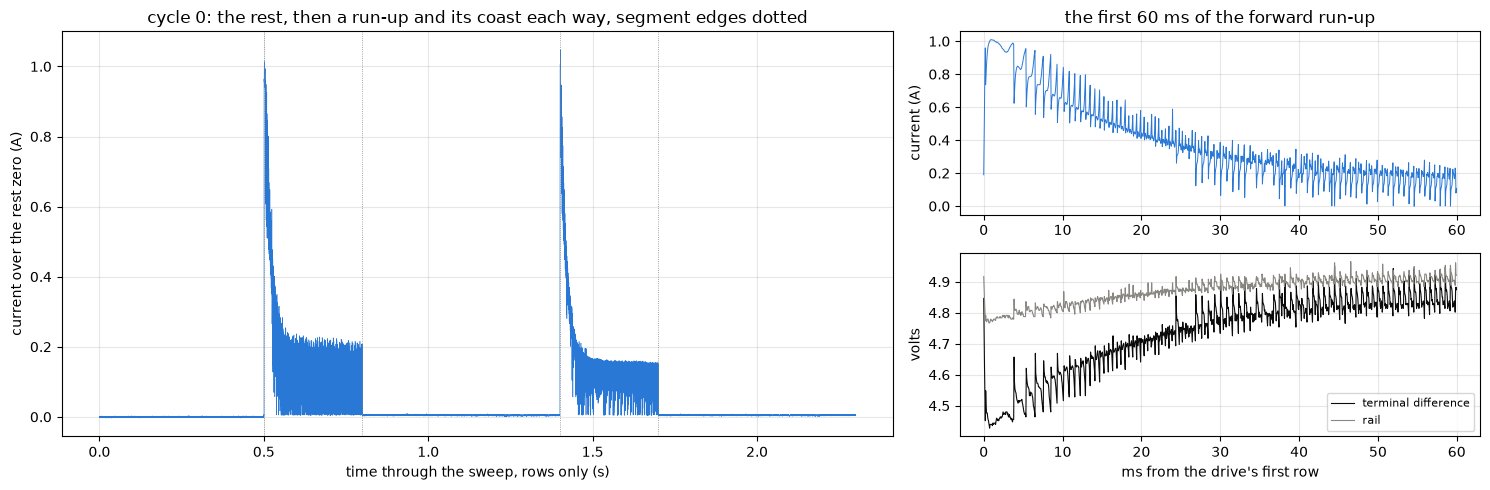

first rows: 0.19 A, peak 1.01 A at 0.90 ms, 0.39 A at 30 ms and 0.111 A over the last 100 ms
terminal difference 4.45 V at 1 to 2 ms and 4.87 V over the last 100 ms, rail 4.78 and 4.92 V


In [5]:
R0 = RUNS[0]                                                             # cycle 0, direction +1
df0, _ = tel.load(cycle_folder(0), BOARD)
z0 = tel.baseline(df0)["current_raw"].median()
ts = np.arange(len(df0)) / FS                                            # time through the sweep as rows, since `tick` restarts at each segment
edges = np.flatnonzero(np.diff(df0["seg"].to_numpy()) != 0) + 1
fig = plt.figure(figsize=(15, 5))
gs = fig.add_gridspec(2, 2, width_ratios=[1.6, 1])
ax = [fig.add_subplot(gs[:, 0]), fig.add_subplot(gs[0, 1])]
ax.append(fig.add_subplot(gs[1, 1], sharex=ax[1]))
ax[0].plot(ts, (df0["current_raw"] - z0) * A_PER_COUNT, lw=0.4, color=BLUE)
for e in edges:
    ax[0].axvline(e / FS, color=MUTED, lw=0.6, ls=":")                   # segment edges, where the streams meet
ax[0].set_xlabel("time through the sweep, rows only (s)"); ax[0].set_ylabel("current over the rest zero (A)")
ax[0].set_title("cycle 0: the rest, then a run-up and its coast each way, segment edges dotted")
t = np.arange(len(R0["i"])) / FS * 1e3
n = int(0.06 * FS)                                                       # the first 60 ms of the run-up
ax[1].plot(t[:n], R0["i"][:n], lw=0.7, color=BLUE)
ax[1].set_ylabel("current (A)"); ax[1].set_title("the first 60 ms of the forward run-up")
ax[2].plot(t[:n], R0["u"][:n], lw=0.8, color=INK, label="terminal difference")
ax[2].plot(t[:n], R0["rail"][:n], lw=0.8, color=MUTED, label="rail")
ax[2].set_xlabel("ms from the drive's first row"); ax[2].set_ylabel("volts"); ax[2].legend(fontsize=8)
for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"first rows: {R0['i'][0]:.2f} A, peak {R0['i'][:40].max():.2f} A at {np.argmax(R0['i'][:40]) / FS * 1e3:.2f} ms, "
      f"{R0['i'][int(0.03 * FS)]:.2f} A at 30 ms and {R0['i'][-2000:].mean():.3f} A over the last 100 ms")
print(f"terminal difference {R0['u'][20:40].mean():.2f} V at 1 to 2 ms and {R0['u'][-2000:].mean():.2f} V over the last 100 ms, "
      f"rail {R0['rail'][20:40].mean():.2f} and {R0['rail'][-2000:].mean():.2f} V")

The current jumps to about an amp in the first millisecond, as fast as the winding's inductance lets it, and then falls as the rotor speeds up and its EMF grows, to 0.39 A at 30 ms and about 0.11 A once the speed has settled. The terminal voltage moves the other way, 4.45 V at the start and 4.87 V at the end, and the rail with it. Both sag under the current, and that sag is part of the curve, since the motor only ever gets what the terminals read. The coast after each run-up starts from full speed and takes about a quarter second to stop.

## Checking the capture

The capture can only be repeated with the motor still assembled, so its quality is checked here before anything is read from it. Five things are checked. Rows lost between the board and the host, the duty held at 100 % through each spin, the current inside the converter's range, the sag of what the motor gets under its own current, and the rows where the current drops out, which bemf-coast found at speed. The ripple count's own failures come with the count further down.

rows missing by the tick count: 0 | rows the board reports dropped: 0 | 100 % held from the first driven row to the end in 6 of 6 run-ups
rows of each spin's stream before the drive starts: 1 to 9, the current channel's largest count 2569 of 4095


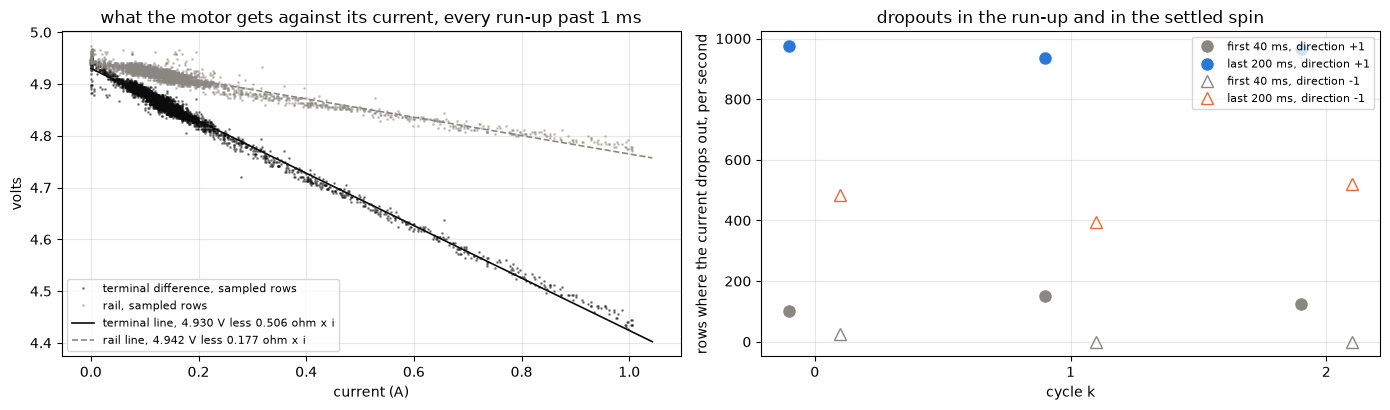

terminal difference 4.930 V less 0.506 ohm x i, rail 4.942 V less 0.177 ohm x i, against terminal-chain's rail sag 0.149 V/A
direction +1: dropouts 125 per s in the first 40 ms and 958 per s in the last 200 ms (935 to 975)
direction -1: dropouts 8 per s in the first 40 ms and 467 per s in the last 200 ms (395 to 520)


In [6]:
Q = pd.DataFrame([{k: r[k] for k in ("k", "dir", "rows_before", "held", "raw_max", "missing", "rows_dropped")} for r in RUNS])
print("rows missing by the tick count:", int(Q["missing"].sum()), "| rows the board reports dropped:", int(Q["rows_dropped"].sum()),
      "| 100 % held from the first driven row to the end in", int(Q["held"].sum()), "of", len(Q), "run-ups")
print(f"rows of each spin's stream before the drive starts: {Q['rows_before'].min()} to {Q['rows_before'].max()}, "
      f"the current channel's largest count {Q['raw_max'].max()} of {BOARD.adc_counts - 1}")

# the supply seen from the motor: the terminal difference and the rail against the current, every row past the first ms,
# as a straight line each. The terminal difference is what the motor gets, the rail is the board's tap before the bridge.
ii = np.concatenate([r["i"][20:] for r in RUNS]); uu = np.concatenate([r["u"][20:] for r in RUNS]); rr = np.concatenate([r["rail"][20:] for r in RUNS])
SUP = np.polyfit(ii, uu, 1)                                              # u = V_s - R_s i, the supply and the bridge as one source
RAIL = np.polyfit(ii, rr, 1)

# rows where the current drops out: under a quarter of the mean of the 2 ms around them, as bemf-coast counts them,
# in the run-up's first 40 ms and in its last 200 ms where the speed has settled
def open_mask(i):
    ref = np.convolve(i, np.ones(41) / 41, mode="same")
    m = i < 0.25 * ref
    m[:40] = False; m[-20:] = False
    return m
for r in RUNS:
    m = open_mask(r["i"])
    r["open"] = m
    r["open_early_per_s"] = m[:int(0.04 * FS)].sum() / 0.04
    r["open_late_per_s"] = m[-int(0.2 * FS):].sum() / 0.2
Q["open_early_per_s"] = [r["open_early_per_s"] for r in RUNS]; Q["open_late_per_s"] = [r["open_late_per_s"] for r in RUNS]

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
sel = np.random.default_rng(0).choice(len(ii), 4000, replace=False)       # a sample of rows, enough to see the band
ax[0].plot(ii[sel], uu[sel], ".", ms=2, color=INK, alpha=0.4, label="terminal difference, sampled rows")
ax[0].plot(ii[sel], rr[sel], ".", ms=2, color=MUTED, alpha=0.4, label="rail, sampled rows")
x = np.linspace(0, ii.max(), 10)
ax[0].plot(x, np.polyval(SUP, x), "-", color=INK, lw=1.2, label=f"terminal line, {SUP[1]:.3f} V less {-SUP[0]:.3f} ohm x i")
ax[0].plot(x, np.polyval(RAIL, x), "--", color=MUTED, lw=1.2, label=f"rail line, {RAIL[1]:.3f} V less {-RAIL[0]:.3f} ohm x i")
ax[0].set_xlabel("current (A)"); ax[0].set_ylabel("volts"); ax[0].set_title("what the motor gets against its current, every run-up past 1 ms")
ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)
for d in (1, -1):
    h = Q[Q["dir"] == d]
    ax[1].plot(h["k"] - 0.1 * d, h["open_early_per_s"], MARK[d], ms=8, color=MUTED, mfc=MUTED if d == 1 else "none", label=f"first 40 ms, direction {d:+d}")
    ax[1].plot(h["k"] - 0.1 * d, h["open_late_per_s"], MARK[d], ms=8, color=DIR_COLOR[d], mfc=DIR_COLOR[d] if d == 1 else "none", label=f"last 200 ms, direction {d:+d}")
ax[1].set_xticks(sorted(Q["k"].unique())); ax[1].set_xlabel("cycle k"); ax[1].set_ylabel("rows where the current drops out, per second")
ax[1].set_title("dropouts in the run-up and in the settled spin"); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"terminal difference {SUP[1]:.3f} V less {-SUP[0]:.3f} ohm x i, rail {RAIL[1]:.3f} V less {-RAIL[0]:.3f} ohm x i, "
      f"against terminal-chain's rail sag {TC['rail_sag_v_per_a']['value']:.3f} V/A")
for d in (1, -1):
    h = Q[Q["dir"] == d]
    print(f"direction {d:+d}: dropouts {h['open_early_per_s'].mean():.0f} per s in the first 40 ms and {h['open_late_per_s'].mean():.0f} per s "
          f"in the last 200 ms ({h['open_late_per_s'].min():.0f} to {h['open_late_per_s'].max():.0f})")

No row is missing, every spin held 100 % from its first driven row to its last, and the current channel peaks at 2569 counts, well inside the converter. The drive starts 1 to 9 rows into each spin's stream, and every reading below starts from the first driven row.

What the motor gets falls along a straight line with its current, 4.930 V less 0.506 ohm times the current, about 4.43 V at an amp, near the stall, and 4.87 V at no load. The rail itself falls 0.177 ohm per amp, close to terminal-chain's 0.149 V per amp, so about two thirds of the drop is past the rail tap, in the bridge, the connector and the leads. The sag is measured row by row and every number below uses the measured terminal volts, so nothing has to model it. A stiffer supply would give a different curve at the stall end, and the line above is how this one compares.

The dropouts are frequent at full speed. In direction +1 the current drops out about 960 times a second over the last 200 ms, almost two rows per revolution, and in direction -1 about 470 times a second. In the first 40 ms, at lower speed and an amp or less, they are 125 a second in direction +1 and 8 in direction -1. bemf-coast found the same pattern at lower speeds, more frequent with speed and in direction +1, and read them as the brush path opening, with moderate to high confidence. At 960 a second the dropout rows are about 5 % of the settled rows. They are left out of the terminal-volts line below and kept in the torque, since a row that reads zero is a moment the rotor got no torque, as no-load-current argues. In the first 40 ms they are under 1 % of the rows, so the choice moves the run-up little. This is a property of the motor at speed and not a fault of the capture, and it is the largest thing in the settled current. The [teardown](../teardown/teardown.ipynb) found three wire fingers on each brush and did not observe brush bounce, so what opens the path at speed is not settled.

## Method

A few symbols carry the notebook. $\omega$ (omega) is the motor's speed in radians per second and $\alpha$ (alpha) its rise, in radians per second squared. $i$ is the current and $u$ the terminal voltage. $J$ is the rotor's inertia, $K_t$ the torque per amp and $K_e$ the back-EMF constant, the same number in SI units. $I_0(\omega)$ is the current a settled spin draws at the speed $\omega$, no-load-current's drag under drive with the reading term out, so $K_t \, I_0(\omega)$ is the drag torque. $R$ is the winding's resistance through the brushes, $V_0$ a drop at the brushes that stays about the same as the current changes, and $L$ the inductance.

The rotor obeys

$$J \, \alpha = K_t \, i - K_t \, I_0(\omega)$$

and the winding

$$u = K_e \, \omega + R \, i + V_0 + L \, \frac{di}{dt}$$

The shaft torque, what the motor has left for a load after its own drag, is $T = J \, \alpha = K_t \, (i - I_0(\omega))$. Read from the speed it needs $J$, and read from the current it needs the drag. The first equation with both sides measured gives $J$.

Every run-up goes through the same steps.

1. The settled speed. With the bridge open the coast's EMF carries the six-per-revolution line with little else, so the strongest line in its first 10 ms seeds the count, and the six-per-revolution line in the spin's current over its last 200 ms, found near that seed, is the settled speed.
2. A rough speed. The terminal volts less $R \, i$ and $L \, di/dt$ with rest-resistance's terminal resistance, over $K_e$, with a constant chosen so the settled part lands on the seed. It only has to be within about 20 % of the truth.
3. The count. The current from 1 ms on, past its rise through the inductance, is resampled onto an even grid of the rough angle, the integral of the rough speed. On that grid the commutation ripple sits at one frequency however fast the rotor speeds up, six cycles per revolution, and a band-pass of +/-25 % around it keeps the three-per-revolution and nine-per-revolution lines out. The band-pass runs forward and back so it shifts no crossing, and each upward crossing, mapped back to time, is a sixth of a turn. The speed counted from the crossings becomes the next pass's rough speed, five passes in all. Before the tenth crossing the rough speed is the current's integral from rest scaled to the count, since the count has too few crossings to lean on that early.
4. The repair. An interval between crossings far longer than its neighbors holds a missed crossing, and one far shorter an extra one. Each is fixed and counted.
5. The speed per turn. One turn over the time of six consecutive intervals, sliding one crossing at a time. A whole turn cancels any unevenness in where the six events sit round the commutator. A window more than 5 % off a quadratic through the 31 around it, or more than 6 % off the other run-ups of the same direction at the same time, holds a crossing too many or too few, and is flagged and left out.
6. The acceleration. A quadratic of angle on time through the crossings within +/-5 ms of a center, every 0.5 ms, with at least two turns of crossings. Its slope is the speed and twice its curvature the acceleration. The current and the terminal volts are averaged over the same span. A fit whose crossings sit more than twice the run-up's median distance off its quadratic holds a bad crossing and is flagged.
7. The stall end. While the speed is low each commutation shows in the current as a drop of more than 0.12 A from one row to the next, so the drops' spacing reads the speed before the count starts. The current's integral from rest through $J$ joins the drops and the count, and the $J$ that puts its angle at 60 degrees per drop over the first turn is a route to $J$ there.
8. $J$. The acceleration on $K_t \, (i - I_0(\omega))$, over the fits where the current is at least 150 mA over the drag, as a line. Its slope is $1/J$, and its intercept, as a current, is a constant drag the curve misses, so a constant error in the drag moves the intercept and not $J$. The fits overlap, twenty of them sharing every crossing, so the line's standard error is the six run-ups' spread over the root of six and not the fit's own covariance. $K_t$ is taken equal to $K_e$, so $J$ scales with $K_e$ and with the current's scale.
9. The terminal volts under rotation. $u - L \, di/dt - K_e \, \omega$ against the current over the turn windows of the first 100 ms, a line whose slope is $R$ and whose intercept is $V_0$, both for the moving rotor.
10. The curve. The shaft torque $J \, \alpha$ with this notebook's $J$, the speed, the current, the output power $T \, \omega$ and the efficiency $T \, \omega / (u \, i)$, one point per acceleration fit. The stall torque is the zero-speed end of a line of the torque on the speed, since the torque from the acceleration is the noisy axis.
11. The model. The two equations integrated from rest with the constants from the earlier notebooks and with this notebook's own, against the measured run-up.

The method changed from the plan in three places once the data came in.

- The plan counted the ripple in fixed windows of whole cycles, as no-load-current does. Through a run-up the ripple's frequency triples within 20 ms, so a fixed window's band-pass either misses the start or lets the neighboring lines in. The count on the rough angle keeps the band fixed in turns. A free search at the settled end also lands on the three-per-revolution line, which is taller than the six-per-revolution line there in every run-up, so the coast seeds it, as bemf-coast does.
- The README defined the torque as $J \, \alpha$ plus the drag. That is the motor's whole torque $K_t \, i$, and its curve would end at the drag torque and not at zero. The curve here is drawn against the shaft torque $J \, \alpha$, the usual performance curve, and $K_t \, (i - I_0)$ checks it.
- The plan added bemf-coast's run-ups at partial duty. At a partial duty the current switches, the crest sample is not the mean and the terminal volts read the rail and not the motor's mean voltage, so those run-ups give other curves and are left out. The curve here is the 100 % one.

### The estimators

One function per step.

In [7]:
BAND = 0.25                       # the band-pass on the rough angle keeps six per revolution +/- this share, so three and nine per revolution stay out
PER = 2 * np.pi / N_R             # rad of shaft per ripple event
NS = 16                           # samples per ripple cycle on the angle grid
HALF = 0.005                      # s, the half width of the local fit that reads the acceleration
SETTLED = 0.1                     # s into the run-up, past which the speed has settled to within a percent or two
RISE = 20                         # rows, 1 ms, the current's rise through the winding's inductance, five time constants
RES_TIMES = 2.0                   # a fit whose crossings sit further off its quadratic than this many times the run's median holds a bad crossing

def spectrum(x):
    # the Hann-windowed amplitude spectrum, zero-padded 8x, and its frequencies
    x = np.asarray(x, float) - np.mean(x)
    n = len(x)
    return np.fft.rfftfreq(8 * n, 1 / FS), np.abs(np.fft.rfft(x * np.hanning(n), 8 * n))

def strongest(x, lo, hi):
    # the frequency of the strongest line between lo and hi Hz
    f, X = spectrum(x)
    m = (f >= lo) & (f <= hi)
    return float(f[m][int(np.argmax(X[m]))])

def coast_seed(r):
    # the settled speed in rad/s, seeded from the coast. With the bridge open the EMF carries the six-per-revolution line
    # with little else, so the strongest line 1 to 11 ms past the cut seeds it, and the line in the spin's own current over
    # its last 200 ms within -5 to +15 % of that seed, since the coast's window runs a little slower than the spin, is the settled speed. A free search in the spin's current lands on the
    # three-per-revolution line, which is taller there.
    co = r["coast"]
    z = int(np.flatnonzero(co["duty_counts"].to_numpy() == 0)[0])         # the cut, the first row with no drive
    e = (((co["vmotor_a"] - co["vmotor_b"]) * r["dir"]).to_numpy(float)[z:] - r["zero_e"]) * V_PER_COUNT
    f_coast = strongest(e[20:220], 150, 6000)
    f_spin = strongest(r["i"][-int(0.2 * FS):], 0.95 * f_coast, 1.15 * f_coast)
    return 2 * np.pi * f_spin / N_R, f_coast, e

def angle_crossings(x, theta, frac=BAND):
    # the upward crossings of the six-per-revolution line, as rough angle. The current is resampled onto an even grid of the
    # rough angle, where the ripple sits at one fixed frequency however fast the rotor speeds up, band-passed there by a
    # second-order filter run forward and back, so it shifts no crossing, and the first and last crossing dropped as the filter's edge.
    keep = np.r_[True, np.diff(theta) > 0]
    grid = np.arange(theta[0], theta[-1], PER / NS)
    xs = np.interp(grid, theta[keep], x[keep])
    sos = butter(2, [1 - frac, 1 + frac], btype="band", fs=NS, output="sos")
    y = sosfiltfilt(sos, xs - xs.mean())
    s = np.flatnonzero((y[:-1] < 0) & (y[1:] >= 0))
    return (grid[s] + (-y[s]) / (y[s + 1] - y[s]) * (PER / NS))[1:-1]

def local_speed(tc, t, n=31):
    # a robust speed at every row: the median of n intervals between crossings around each, interpolated, nan before the first
    iv = np.diff(tc)
    h = n // 2
    med = np.array([np.median(iv[max(0, j - h):j + h + 1]) for j in range(len(iv))])
    return np.interp(t, (tc[1:] + tc[:-1]) / 2, PER / med, left=np.nan)

def repair(tc, short=0.7, long=1.5):
    # an interval much shorter than the intervals around it holds an extra crossing, and the crossing at whichever end makes the
    # merged interval closest to the local one is dropped; an interval much longer holds a missed crossing, and the missing ones
    # are spread evenly through it. One fix at a time, the local interval re-read after each. Returns the times and the counts.
    tc = np.asarray(tc, float).copy()
    added = removed = 0
    for _ in range(500):
        iv = np.diff(tc)
        med = pd.Series(iv).rolling(15, center=True, min_periods=3).median().to_numpy()
        ratio = iv / med
        j = int(np.argmin(ratio))
        if ratio[j] < short:
            cands = []
            if j > 0:
                cands.append((abs((iv[j - 1] + iv[j]) / med[j] - 1), j))          # drop the crossing at the interval's start
            if j + 1 < len(iv):
                cands.append((abs((iv[j] + iv[j + 1]) / med[j] - 1), j + 1))      # or the one at its end
            err, drop = min(cands)
            if err < 0.35:
                tc = np.delete(tc, drop); removed += 1
                continue
        j = int(np.argmax(ratio))
        if ratio[j] > long:
            m = int(round(ratio[j]))
            tc = np.insert(tc, j + 1, tc[j] + iv[j] * np.arange(1, m) / m); added += m - 1
            continue
        break
    return tc, added, removed

def count_speed(r, passes=5):
    # the crossings of one run-up. The first rough speed is the EMF the terminal difference leaves through r_term, with a
    # constant chosen so the settled part lands on the seed. Each pass then re-reads the crossings with the speed the last
    # pass counted. Before the tenth crossing the rough speed is the current's integral from rest, scaled to the count there,
    # since the count has too few crossings to lean on that early and the integral has the right shape.
    i, u = r["i"], r["u"]
    t = np.arange(len(i)) / FS
    w_seed, f_coast, e_coast = coast_seed(r)
    e = u - RR["r_term_median_ohm"]["value"] * i - L_H * np.gradient(i) * FS
    e = np.convolve(e, np.ones(41) / 41, mode="same")
    w = np.maximum(e - (e[t > 0.2].mean() - KE * w_seed), 0) / KE
    for _ in range(passes):
        theta = np.cumsum(w) / FS
        c = angle_crossings(i[RISE:], theta[RISE:])                       # past the current's rise, which would ring the filter
        c = c[c > theta[RISE] + 2 * PER]                                  # and two more cycles off the start, where the filter's edge sits
        tc = np.interp(c, theta, t)
        tc, added, removed = repair(tc)
        w = local_speed(tc, t)
        t10 = tc[9]
        w_int = np.cumsum(i - I0(0.0)) / FS                              # the current's integral from rest, the drag held at its low-speed value
        w_int *= np.interp(t10, t, w) / np.interp(t10, t, w_int)
        w = np.where(t < t10, w_int, w)
    return tc, w_seed, f_coast, e_coast, added, removed

def rev_table(r, tc):
    # one row per revolution window, sliding one event at a time: the speed is one turn over the time of N_R intervals, which
    # cancels any unevenness in where the events sit round the turn, and the current and volts are the means over the same rows,
    # with the dropout rows left out and kept as read beside them
    i, u, m = r["i"], r["u"], r["open"]
    rows = []
    for j in range(len(tc) - N_R):
        a, b = int(np.ceil(tc[j] * FS)), int(np.floor(tc[j + N_R] * FS))
        keep = ~m[a:b]
        rows.append({"t": (tc[j] + tc[j + N_R]) / 2, "w": 2 * np.pi / (tc[j + N_R] - tc[j]), "i_read": i[a:b].mean(),
                     "i": i[a:b][keep].mean(), "u": u[a:b][keep].mean(), "didt": (i[b] - i[a]) / ((b - a) / FS)})
    return pd.DataFrame(rows)

def fit_table(r, tc, half=HALF, step=0.0005):
    # the acceleration: a quadratic of angle on time through the crossings within +/-half of each center, at least two turns'
    # worth, every step seconds, with the current's mean over the same span
    th = np.arange(len(tc)) * PER
    ci = np.r_[0, np.cumsum(r["i"])]
    cu = np.r_[0, np.cumsum(r["u"])]
    rows = []
    for tm in np.arange(tc[0] + half, tc[-1] - half, step):
        m = (tc >= tm - half) & (tc <= tm + half)
        if m.sum() < 2 * N_R + 1:
            continue
        p = np.polyfit(tc[m] - tm, th[m], 2)
        res = th[m] - np.polyval(p, tc[m] - tm)                          # how far the crossings sit off the quadratic, in rad
        a, b = int(round((tm - half) * FS)), int(round((tm + half) * FS))
        rows.append({"t": tm, "w": p[1], "alpha": 2 * p[0], "i": (ci[b] - ci[a]) / (b - a), "u": (cu[b] - cu[a]) / (b - a),
                     "n": int(m.sum()), "res_deg": np.degrees(res.std())})
    return pd.DataFrame(rows)

### Every run-up through the count

The count's crossings, its repairs, and the settled speed it reaches against the seed.

In [8]:
REV, FIT, CNT = [], [], []
for r in RUNS:
    tc, w_seed, f_coast, e_coast, added, removed = count_speed(r)
    r.update(tc=tc, w_seed=w_seed, f_coast=f_coast, e_coast=e_coast)
    tag = {"k": r["k"], "dir": r["dir"]}
    REV.append(rev_table(r, tc).assign(**tag)); FIT.append(fit_table(r, tc).assign(**tag))
    late = tc[tc > SETTLED]
    CNT.append({**tag, "crossings": len(tc), "added": added, "removed": removed, "first_ms": tc[0] * 1e3,
                "settled_rev_s": (len(late) - 1) / (late[-1] - late[0]) / N_R, "seed_rev_s": w_seed / (2 * np.pi), "coast_line_rev_s": f_coast / N_R})
REV, FIT, CNT = pd.concat(REV, ignore_index=True), pd.concat(FIT, ignore_index=True), pd.DataFrame(CNT)
for T in (REV, FIT):
    T["rev_s"] = T["w"] / (2 * np.pi)
# a turn window that holds a crossing too many or too few reads 7/6 or 5/6 of its neighbors. Each window is held against a
# quadratic in time through the 31 windows around it, so the run-up's own rise does not count as a fault, and windows more
# than 5 % off are flagged, left out of everything below, and counted here.
def flag_windows(t, w, n=15, tol=0.05):
    # for each window, a quadratic in time through the 31 windows around it, refitted three times without the ones more than
    # tol off it, and the window's own distance from the last fit
    ok = np.ones(len(w), bool)
    for j in range(len(w)):
        sl = slice(max(0, j - n), j + n + 1)
        tt, ww = t[sl] - t[j], w[sl]
        keep = np.ones(len(ww), bool)
        for _ in range(3):
            p = np.polyfit(tt[keep], ww[keep], 2)
            keep = np.abs(ww / np.polyval(p, tt) - 1) <= tol
            if keep.sum() < 5:
                break
        ok[j] = abs(w[j] / np.polyval(p, 0.0) - 1) <= tol
    return ok
REV["ok"] = True
for (k, d), h in REV.groupby(["k", "dir"]):
    REV.loc[h.index, "ok"] = flag_windows(h["t"].to_numpy(), h["w"].to_numpy())
# a stretch where a run-up gains or loses a crossing every turn for several turns fools a local fit, so each window is also
# held against the other run-ups of the same direction at the same time, which repeat closely, and flagged if more than
# 6 % off their median
GRID = np.arange(0, 0.3, 0.0005)
for d in (1, -1):
    curves = []
    for k, h in REV[(REV["dir"] == d) & REV["ok"]].groupby("k"):
        curves.append(np.interp(GRID, h["t"], h["w"], left=np.nan, right=np.nan))
    with np.errstate(all="ignore"), warnings.catch_warnings():
        warnings.simplefilter("ignore")                               # a time no run-up reaches has no median, and stays nan
        ref = np.nanmedian(np.array(curves), axis=0)
    h = REV[REV["dir"] == d]
    off = np.abs(h["w"] / np.interp(h["t"], GRID, ref) - 1) > 0.06
    REV.loc[h.index[off.to_numpy()], "ok"] = False
CNT = CNT.merge(REV.groupby(["k", "dir"])["ok"].agg(lambda x: int((~x).sum())).rename("windows_flagged").reset_index())
# a fit is flagged when its crossings sit more than RES_TIMES times the run's median distance off its quadratic
FIT["res_ok"] = FIT["res_deg"] <= RES_TIMES * FIT.groupby(["k", "dir"])["res_deg"].transform("median")
CNT = CNT.merge(FIT.groupby(["k", "dir"])["res_ok"].agg(lambda x: int((~x).sum())).rename("fits_flagged").reset_index())
ALL_REV = REV
REV = REV[REV["ok"]].copy()
show(CNT.round(2), n=None)
print(f"{len(REV)} revolution windows and {len(FIT)} acceleration fits over {len(RUNS)} run-ups, "
      f"{int(CNT['added'].sum())} crossings added and {int(CNT['removed'].sum())} removed by the repair, of {int(CNT['crossings'].sum())}")
print(f"{int(CNT['windows_flagged'].sum())} turn windows flagged of {len(ALL_REV)}, in "
      + ", ".join(f"k{int(c.k)} {int(c.dir):+d} {int(c.windows_flagged)}" for c in CNT.itertuples()))
print(f"the settled count over the seed: {((CNT['settled_rev_s'] / CNT['seed_rev_s'] - 1) * 100).min():+.2f} to {((CNT['settled_rev_s'] / CNT['seed_rev_s'] - 1) * 100).max():+.2f} %")

,k,dir,crossings,added,removed,first_ms,settled_rev_s,seed_rev_s,coast_line_rev_s,windows_flagged,fits_flagged
0,0,1,902,0,0,5.970,538.290,537.290,525.000,2,0
1,0,-1,936,1,0,5.960,558.510,558.540,541.670,7,0
2,1,1,902,0,0,5.770,538.390,540.210,525.000,0,0
3,1,-1,936,1,0,5.930,558.510,556.560,537.500,33,26
4,2,1,902,1,0,5.140,536.750,535.620,525.000,1,1
5,2,-1,936,1,0,5.800,556.340,556.560,537.500,38,60


5397 revolution windows and 3404 acceleration fits over 6 run-ups, 4 crossings added and 0 removed by the repair, of 5514
81 turn windows flagged of 5478, in k0 +1 2, k0 -1 7, k1 +1 0, k1 -1 33, k2 +1 1, k2 -1 38
the settled count over the seed: -0.34 to +0.35 %


Each forward run-up holds 902 crossings and each reverse one 936, about 150 and 156 turns in 300 ms. The repair added four crossings over the six run-ups and removed none. The settled count, the crossings past 100 ms, lands within 0.35 % of the seed in every run-up, so the count and the coast's line agree on the settled speed, which is 538 rev/s forward and 557 rev/s reverse.

The flags are nearly all in direction -1. 81 turn windows of 5478 are left out, 78 of them in direction -1, most in cycles 1 and 2 at 50 to 110 ms and at 225 to 246 ms, where a crossing is missed or doubled for a turn or a few. In cycle 2 at 69 to 75 ms the count gained a crossing every turn for about six turns, which a local fit alone did not catch, and the check against the other two run-ups of the same direction did. 87 acceleration fits of 3404 are flagged, 86 of them in direction -1 of cycles 1 and 2. In direction -1 the six-per-revolution line is a smaller share of the current's ripple, and the crossings of a fit sit 3.9 degrees off its quadratic in the median against 3.0 degrees in direction +1. The flags are local and the windows on either side read normally, so the count is good with these left out. Most likely the ripple in direction -1 is shaped differently by the brushes, low confidence, and the half-rate line bemf-coast found is part of it.

The settled speed is not quite flat. From 100 to 300 ms the median speed creeps up from 530 to 543 rev/s in direction +1 and from 551 to 561 rev/s in direction -1, about 2 %, the drive's extra drag early in a run fading as no-load-current found it does over a few hundred milliseconds. The no-load speeds above are the means over the last 200 ms, so a longer spin would end a percent or so higher.

### One run-up through the count

The forward run-up of cycle 0. Left, the current's first 12 ms with each of the count's crossings dotted and the sharp drops the next section reads marked. Middle, the speed per turn, with the speed the current gives through no-load-current's working $J$ from rest beside it. Right, the settled current's spectrum, with the lines at one, three and six per revolution of the settled speed marked. The thing to see is where the count starts and whether the speed it reads follows the current's own integral.

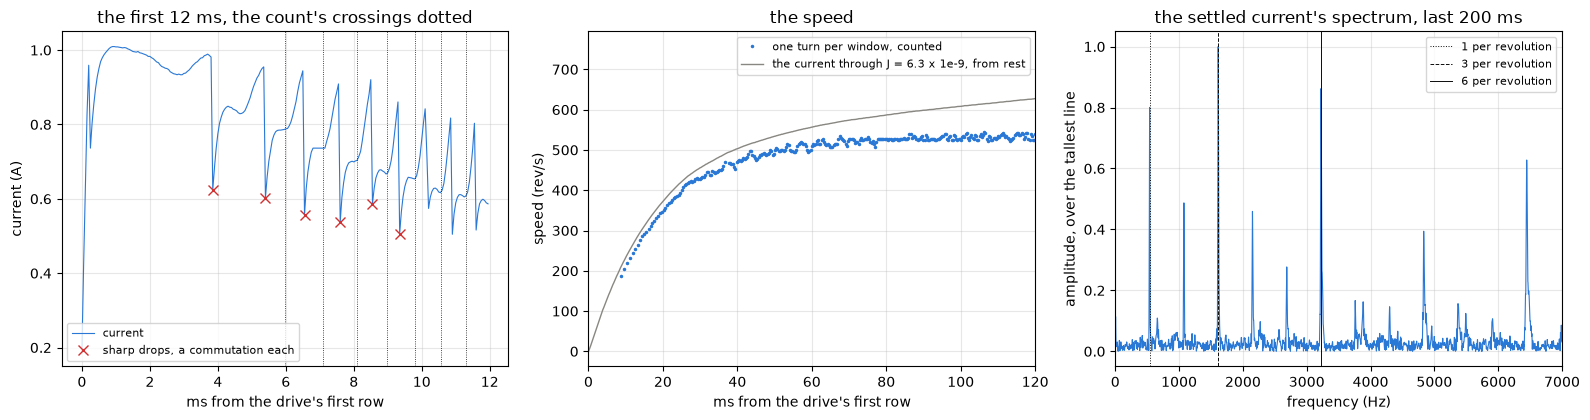

cycle 0 direction +1: first kept crossing 5.97 ms, the first turn's window centered at 8.6 ms at 188 rev/s, settled at 537 rev/s


In [9]:
r = RUNS[0]
t = np.arange(len(r["i"])) / FS
rv = REV[(REV["k"] == r["k"]) & (REV["dir"] == r["dir"])]
w_int = np.cumsum(KT * (r["i"] - I0(np.interp(t, rv["t"], rv["w"], left=0)))) / FS / J_GUESS   # the speed the current gives through J, from rest
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
n = int(0.012 * FS)                                                       # the first 12 ms
sos = butter(2, [1 - BAND, 1 + BAND], btype="band", fs=NS, output="sos")
ax[0].plot(t[:n] * 1e3, r["i"][:n], lw=0.8, color=BLUE, label="current")
for c in r["tc"][r["tc"] < t[n]]:
    ax[0].axvline(c * 1e3, color=INK, lw=0.6, ls=":")                    # each crossing, a sixth of a turn
dips = np.flatnonzero(np.diff(r["i"][:n]) < -0.12) + 1                     # the sharp drops the stall end reads, marked
dips = dips[(dips > int(0.0015 * FS)) & (dips < (r["tc"][0] + 0.004) * FS)]; dips = dips[np.r_[True, np.diff(dips) > 3]][:7]   # as the stall end reads them
ax[0].plot(t[dips] * 1e3, r["i"][dips], "x", ms=7, color=RED, label="sharp drops, a commutation each")
ax[0].legend(fontsize=8)
ax[0].set_xlabel("ms from the drive's first row"); ax[0].set_ylabel("current (A)"); ax[0].set_title("the first 12 ms, the count's crossings dotted")
ax[1].plot(rv["t"] * 1e3, rv["rev_s"], ".", ms=3, color=BLUE, label="one turn per window, counted")
ax[1].plot(t * 1e3, w_int / (2 * np.pi), "-", lw=1, color=MUTED, label=f"the current through J = {J_GUESS * 1e9:.1f} x 1e-9, from rest")
ax[1].set_xlim(0, 120); ax[1].set_xlabel("ms from the drive's first row"); ax[1].set_ylabel("speed (rev/s)"); ax[1].set_title("the speed")
ax[1].legend(fontsize=8)
f, X = spectrum(r["i"][-int(0.2 * FS):])
ax[2].plot(f, X / X[f > 150].max(), lw=0.8, color=BLUE)
for m_, ls in ((1, ":"), (3, "--"), (6, "-")):
    ax[2].axvline(r["w_seed"] / (2 * np.pi) * m_, color=INK, lw=0.7, ls=ls, label=f"{m_} per revolution")
ax[2].set_xlim(0, 7000); ax[2].set_xlabel("frequency (Hz)"); ax[2].set_ylabel("amplitude, over the tallest line")
ax[2].set_title("the settled current's spectrum, last 200 ms"); ax[2].legend(fontsize=8)
for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"cycle {r['k']} direction {r['dir']:+d}: first kept crossing {r['tc'][0] * 1e3:.2f} ms, the first turn's window centered at "
      f"{rv['t'].iloc[0] * 1e3:.1f} ms at {rv['rev_s'].iloc[0]:.0f} rev/s, settled at {r['w_seed'] / (2 * np.pi):.0f} rev/s")

The first crossing kept is at 6.0 ms, and the first full turn's window is centered at 8.6 ms at 188 rev/s. The crossings the band-pass gives in the first turn sit at its edge and are dropped. The current itself shows each commutation earlier than that, as a sharp drop of one row, at 3.9, 5.4 and 6.6 ms here. From the first window on the count follows the current's integral closely through the first 30 ms, and sits under it after that, where the drag the settled curve misses adds up. The settled spectrum shows why a free search fails there. The line at three per revolution is the tallest, the six-per-revolution line is a little lower, and the once-per-revolution line is strong in this direction, the pattern a disturbance at one place on the commutator would make.

### The stall end

The first milliseconds of every run-up, where the speed is too low for the count. Before the count starts, each commutation shows in the current as a drop of more than 0.12 A from one row to the next, and consecutive drops are a sixth of a turn apart, so their spacing is a speed. The figure puts the drops' speeds, the count's first turns and the current's integral from rest through no-load-current's working $J$ on one axis for all six run-ups. The thing to see is whether the three agree where they overlap, and how close to rest the drops reach. Below the figure, the same in numbers, the $J$ that puts the integral's angle at exactly 60 degrees per drop over the first turn, and the current and the terminal volts at 0.8 to 1.5 ms, past the current's rise and with the rotor barely moving.

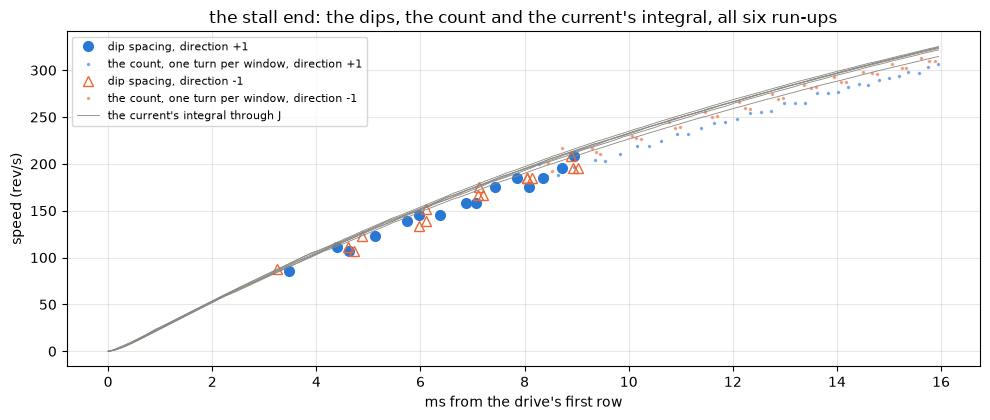

first dip 2.3 to 4.0 ms, first kept crossing 5.1 to 6.0 ms, the first turn's window centered at 8.3 to 8.7 ms and 188 to 217 rev/s
the dips read 85 rev/s and up from 3.2 ms, and the integral sits +5.9 % from them in the median (+1.7 to +11.0 % from the 16th to the 84th percentile)
over the first two counted turns the integral sits -1.5 to +8.1 % from the count, +4.7 % on average
the J that puts the integral's angle at 60 degrees per dip over the first turn: 6.73 x 1e-9 kg m^2 (6.28 to 7.02), with the drag held at 44 mA
0.8 to 1.5 ms, past the current's rise: 1.007 A (0.997 to 1.015) at 4.432 V, the rotor at about 29 rev/s by the current's integral


In [10]:
# where the count starts in each run-up, against the speed the current gives from rest through J. The comparison runs over
# each run-up's first two turns of counted windows. Before the count starts, each commutation shows in the current as a
# drop of more than 0.12 A from one row to the next, and those drops are a sixth of a turn apart, so their spacing reads
# the speed from about 2 ms on and the current's integral can be held against it. The integral's angle over the dips
# should be 60 degrees per dip, and the J that makes it so is a route to J at the stall end.
DIP_A = 0.12                      # A, a drop from one row to the next larger than this is a commutation at low speed
N_DIPS = 7                        # the first seven dips, six intervals, a turn
rows, DIPS = [], []
for r in RUNS:
    i = r["i"]
    t = np.arange(len(i)) / FS
    rv = REV[(REV["k"] == r["k"]) & (REV["dir"] == r["dir"])]
    w_int = np.cumsum(KT * (i - I0(np.interp(t, rv["t"], rv["w"], left=0)))) / FS / J_GUESS
    th_int = np.cumsum(w_int) / FS
    first = rv.iloc[:2 * N_R]
    k = np.flatnonzero(np.diff(i) < -DIP_A) + 1                           # rows that open a sharp drop
    k = k[(t[k] > 0.0015) & (t[k] < r["tc"][0] + 0.004)]                  # past the current's rise, up to the count's start
    k = k[np.r_[True, np.diff(k) > 3]][:N_DIPS]                           # the first row of each drop
    ev = t[k]
    dth = np.degrees(np.diff(np.interp(ev, t, th_int)))                   # the integral's angle between consecutive dips
    for a, b in zip(ev[:-1], ev[1:]):
        DIPS.append({"k": r["k"], "dir": r["dir"], "t": (a + b) / 2, "rev_s": 1 / N_R / (b - a),
                     "int_rev_s": np.interp((a + b) / 2, t, w_int) / (2 * np.pi)})
    rows.append({"k": r["k"], "dir": r["dir"], "first_dip_ms": ev[0] * 1e3, "first_ms": r["tc"][0] * 1e3, "first_window_ms": first["t"].iloc[0] * 1e3,
                 "first_rev_s": first["rev_s"].iloc[0], "int_over_count_pct": (np.interp(first["t"], t, w_int) / first["w"] - 1).mean() * 100,
                 "j_dips": J_GUESS * dth.mean() / (360 / N_R),
                 "stall_i": i[int(0.0008 * FS):int(0.0015 * FS)].mean(), "stall_u": r["u"][int(0.0008 * FS):int(0.0015 * FS)].mean(),
                 "w_int_1ms_rev_s": w_int[int(0.0012 * FS)] / (2 * np.pi)})
FIRST, DIPS = pd.DataFrame(rows), pd.DataFrame(DIPS)
fig, ax = plt.subplots(figsize=(10, 4.3))
for d in (1, -1):
    h = DIPS[DIPS["dir"] == d]
    ax.plot(h["t"] * 1e3, h["rev_s"], MARK[d], ms=7, color=DIR_COLOR[d], mfc=DIR_COLOR[d] if d == 1 else "none", label=f"dip spacing, direction {d:+d}")
    rv = REV[(REV["dir"] == d) & (REV["t"] < 0.016)]
    ax.plot(rv["t"] * 1e3, rv["rev_s"], ".", ms=3, color=DIR_COLOR[d], alpha=0.5, label=f"the count, one turn per window, direction {d:+d}")
for r in RUNS:
    t = np.arange(len(r["i"])) / FS
    rv = REV[(REV["k"] == r["k"]) & (REV["dir"] == r["dir"])]
    w_int = np.cumsum(KT * (r["i"] - I0(np.interp(t, rv["t"], rv["w"], left=0)))) / FS / J_GUESS
    ax.plot(t[:int(0.016 * FS)] * 1e3, w_int[:int(0.016 * FS)] / (2 * np.pi), "-", lw=0.6, color=MUTED, label="the current's integral through J" if r is RUNS[0] else None)
ax.set_xlabel("ms from the drive's first row"); ax.set_ylabel("speed (rev/s)"); ax.set_title("the stall end: the dips, the count and the current's integral, all six run-ups")
ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()
print(f"first dip {FIRST['first_dip_ms'].min():.1f} to {FIRST['first_dip_ms'].max():.1f} ms, first kept crossing {FIRST['first_ms'].min():.1f} to {FIRST['first_ms'].max():.1f} ms, "
      f"the first turn's window centered at {FIRST['first_window_ms'].min():.1f} to {FIRST['first_window_ms'].max():.1f} ms and {FIRST['first_rev_s'].min():.0f} to {FIRST['first_rev_s'].max():.0f} rev/s")
print(f"the dips read {DIPS['rev_s'].min():.0f} rev/s and up from {DIPS['t'].min() * 1e3:.1f} ms, and the integral sits "
      f"{((DIPS['int_rev_s'] / DIPS['rev_s'] - 1) * 100).median():+.1f} % from them in the median ({((DIPS['int_rev_s'] / DIPS['rev_s'] - 1) * 100).quantile(0.16):+.1f} to "
      f"{((DIPS['int_rev_s'] / DIPS['rev_s'] - 1) * 100).quantile(0.84):+.1f} % from the 16th to the 84th percentile)")
print(f"over the first two counted turns the integral sits {FIRST['int_over_count_pct'].min():+.1f} to {FIRST['int_over_count_pct'].max():+.1f} % "
      f"from the count, {FIRST['int_over_count_pct'].mean():+.1f} % on average")
print(f"the J that puts the integral's angle at 60 degrees per dip over the first turn: {FIRST['j_dips'].mean() * 1e9:.2f} x 1e-9 kg m^2 "
      f"({FIRST['j_dips'].min() * 1e9:.2f} to {FIRST['j_dips'].max() * 1e9:.2f}), with the drag held at {I0(0) * 1e3:.0f} mA")
print(f"0.8 to 1.5 ms, past the current's rise: {FIRST['stall_i'].mean():.3f} A ({FIRST['stall_i'].min():.3f} to {FIRST['stall_i'].max():.3f}) "
      f"at {FIRST['stall_u'].mean():.3f} V, the rotor at about {FIRST['w_int_1ms_rev_s'].mean():.0f} rev/s by the current's integral")

The count starts 5.1 to 6.0 ms into every run-up, and its first turn's window sits at 8.3 to 8.7 ms and 188 to 217 rev/s, about a third of the settled speed. The acceleration fits need two turns and start at about 10.6 ms and 226 rev/s. So the count does not read the curve's low-speed end, from rest to about 200 rev/s.

That end is read three ways instead. The sharp drops start 2.3 to 4.0 ms into the run-ups and read the speed from 85 rev/s on, and the current's integral through no-load-current's working $J$ sits +5.9 % from them in the median, +1.7 to +11.0 % from the 16th to the 84th percentile, a spread that is mostly the 50 us row the drops are timed to. Over the first two counted turns the integral sits -1.5 to +8.1 % from the count, +4.7 % on average. So the drops, the count and the integral agree to about 6 % where they meet, the integral a few percent high on both, which a $J$ a few percent over 6.3 would close, and the integral carries the speed back to rest with $J$'s uncertainty as its scale. The $J$ that puts the integral's angle at 60 degrees per drop over the first turn is 6.73 x $10^{-9}$ kg m$^2$, 6.28 to 7.02 over the six, with the drag held at its lowest measured speed's 44 mA, about 4 % of the current there. That is a route to $J$ at the stall end, and the next section sets it beside the others. And the stall itself is read directly. At 0.8 to 1.5 ms the current is past its rise, 1.007 A at 4.43 V with a spread of 0.02 A over the six, and the rotor has reached about 29 rev/s, so its EMF is about 0.2 V. That point is the curve's stall end, with the small EMF added back below. The performance curve's low-speed part is drawn between that point and the first counted fit, and the line through the counted part extrapolated to zero speed is the check on it.

## Results

### The inertia from the run-up

Left, every acceleration fit against the current over the drag curve at its speed, both directions, with the line over the fits 150 mA and more over the drag. Right, the ratio $K_t \, (i - I_0) / \alpha$ fit by fit against the time into the run-up, with no-load-current's bracket shaded. The thing to see is whether the acceleration follows the current in a line through the origin, and where the ratio settles while the current is large.

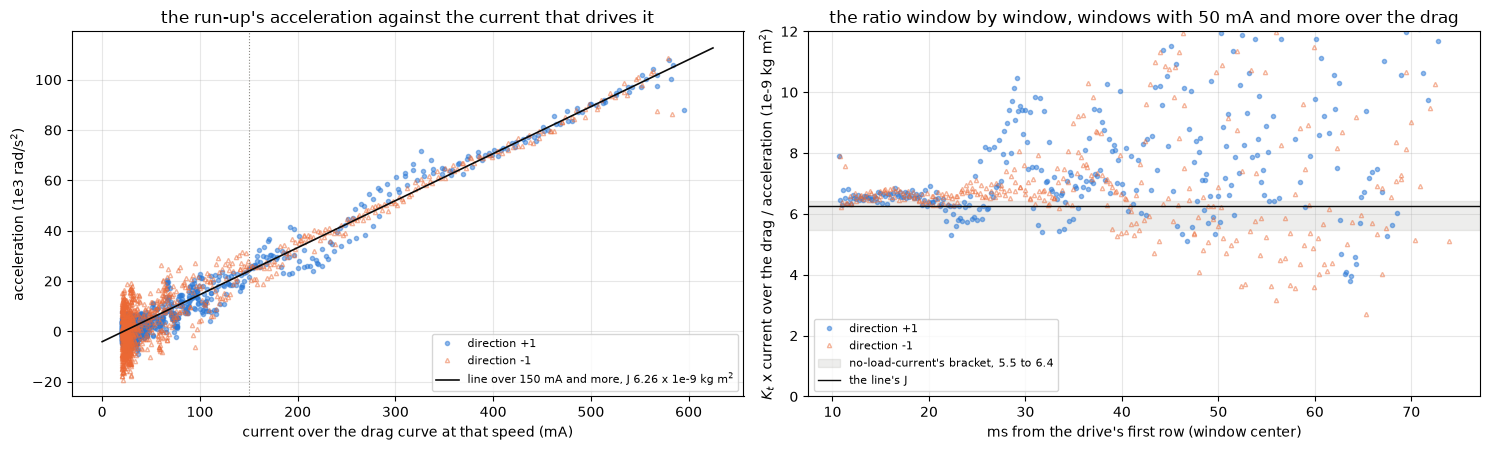

325 windows from 10.6 to 39.4 ms, 226 to 486 rev/s, 150 to 595 mA over the drag
line: J 6.255 +/- 0.083 x 1e-9 kg m^2 over the six run-ups (+/- 0.062 by the line's own covariance), a constant drag the curve misses +21.9 mA, with the 7.4 V curve 6.299 and +17.2 mA
per run-up: k0 -1 6.04 (+32 mA), k0 +1 6.12 (+24 mA), k1 -1 6.23 (+20 mA), k1 +1 6.17 (+26 mA), k2 -1 6.61 (+11 mA), k2 +1 6.36 (+19 mA)
  direction +1: 6.215
  direction -1: 6.295
ratio, median over the windows: drag curve at 5.0 V 6.65, drag curve at 7.4 V 6.61, plus 17 mA of early-run drag 6.31, plus 36 mA of early-run drag 5.95


In [11]:
EX_MIN = 0.15                    # A, the windows used: the drive's current at least this far over the drag, three or more times it
FIT["ex"] = FIT["i"] - I0(FIT["w"])                                    # the current that goes into speeding the rotor up
FIT["ex_hi"] = FIT["i"] - I0_HI(FIT["w"])                              # the same with the 7.4 V drag curve
FIT["j"] = KT * FIT["ex"] / FIT["alpha"]                               # the ratio, window by window
use = FIT[(FIT["ex"] >= EX_MIN) & FIT["res_ok"]]

def j_line(g, col="ex"):
    # the acceleration on Kt x the current over the drag, a line: its slope is 1/J and its intercept, as a current, is a constant
    # drag the curve misses. The acceleration is the noisy axis, so it is the one regressed.
    p, cov = np.polyfit(KT * g[col], g["alpha"], 1, cov=True)
    j = 1 / p[0]
    return {"j": j, "j_se": np.sqrt(cov[0, 0]) * j ** 2, "extra_a": -p[1] * j / KT, "n": len(g)}

LINE = j_line(use)
LINE_HI = j_line(use, "ex_hi")
PER_RUN = pd.DataFrame([{"k": k, "dir": d, **j_line(g)} for (k, d), g in use.groupby(["k", "dir"])])
# the fits sit 0.5 ms apart over +/-5 ms each, so twenty of them share every crossing, and the line's own covariance counts
# them as independent. The pooled line's standard error is the run-ups' spread over the root of their number instead.
J_SE_FIT = LINE["j_se"]
LINE["j_se"] = PER_RUN["j"].std() / np.sqrt(len(PER_RUN))
EARLY = {lvl: NL["early_run_excess_a_by_level"][lvl]["40 to 75 ms"]["value"] for lvl in ("5 V", "7.4 V")}   # the drive's extra drag early in a run
RATIO = {"drag curve at 5.0 V": use["j"].median(),
         "drag curve at 7.4 V": (KT * use["ex_hi"] / use["alpha"]).median(),
         f"plus {EARLY['5 V'] * 1e3:.0f} mA of early-run drag": (KT * (use["ex"] - EARLY["5 V"]) / use["alpha"]).median(),
         f"plus {EARLY['7.4 V'] * 1e3:.0f} mA of early-run drag": (KT * (use["ex"] - EARLY["7.4 V"]) / use["alpha"]).median()}

fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
x = np.linspace(0, use["ex"].max() * 1.05, 10)
for d in (1, -1):
    h = FIT[(FIT["dir"] == d) & (FIT["ex"] > 0.02) & FIT["res_ok"]]
    ax[0].plot(h["ex"] * 1e3, h["alpha"] / 1e3, MARK[d], ms=3, color=DIR_COLOR[d], mfc=DIR_COLOR[d] if d == 1 else "none", alpha=0.5, label=f"direction {d:+d}")
ax[0].plot(x * 1e3, (KT * x / LINE["j"] - KT * LINE["extra_a"] / LINE["j"]) / 1e3, "-", color=INK, lw=1.2,
           label=f"line over {EX_MIN * 1e3:.0f} mA and more, J {LINE['j'] * 1e9:.2f} x 1e-9 kg m$^2$")
ax[0].axvline(EX_MIN * 1e3, color=MUTED, lw=0.8, ls=":")
ax[0].set_xlabel("current over the drag curve at that speed (mA)"); ax[0].set_ylabel("acceleration (1e3 rad/s$^2$)")
ax[0].set_title("the run-up's acceleration against the current that drives it"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)
for d in (1, -1):
    h = FIT[(FIT["dir"] == d) & (FIT["ex"] > 0.05) & FIT["res_ok"]]
    ax[1].plot(h["t"] * 1e3, h["j"] * 1e9, MARK[d], ms=3, color=DIR_COLOR[d], mfc=DIR_COLOR[d] if d == 1 else "none", alpha=0.5, label=f"direction {d:+d}")
lo, hi = NL["j_kg_m2"]["lo"] * 1e9, NL["j_kg_m2"]["hi"] * 1e9
ax[1].axhspan(lo, hi, color=MUTED, alpha=0.15, label=f"no-load-current's bracket, {lo:.1f} to {hi:.1f}")
ax[1].axhline(LINE["j"] * 1e9, color=INK, lw=1, label="the line's J")
ax[1].set_ylim(0, 12); ax[1].set_xlabel("ms from the drive's first row (window center)"); ax[1].set_ylabel("$K_t$ x current over the drag / acceleration (1e-9 kg m$^2$)")
ax[1].set_title("the ratio window by window, windows with 50 mA and more over the drag"); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"{len(use)} windows from {use['t'].min() * 1e3:.1f} to {use['t'].max() * 1e3:.1f} ms, {use['rev_s'].min():.0f} to {use['rev_s'].max():.0f} rev/s, "
      f"{use['ex'].min() * 1e3:.0f} to {use['ex'].max() * 1e3:.0f} mA over the drag")
print(f"line: J {LINE['j'] * 1e9:.3f} +/- {LINE['j_se'] * 1e9:.3f} x 1e-9 kg m^2 over the six run-ups (+/- {J_SE_FIT * 1e9:.3f} by the line's own covariance), "
      f"a constant drag the curve misses {LINE['extra_a'] * 1e3:+.1f} mA, "
      f"with the 7.4 V curve {LINE_HI['j'] * 1e9:.3f} and {LINE_HI['extra_a'] * 1e3:+.1f} mA")
print("per run-up: " + ", ".join(f"k{int(p.k)} {int(p.dir):+d} {p.j * 1e9:.2f} ({p.extra_a * 1e3:+.0f} mA)" for p in PER_RUN.itertuples()))
for d in (1, -1):
    print(f"  direction {d:+d}: {PER_RUN[PER_RUN['dir'] == d]['j'].mean() * 1e9:.3f}")
print("ratio, median over the windows: " + ", ".join(f"{k} {v * 1e9:.2f}" for k, v in RATIO.items()))

The acceleration follows the current over the drag on one line. Over 325 fits from 10.6 to 39.4 ms, 226 to 486 rev/s and 150 to 595 mA over the drag, the line gives $J$ = 6.26 +/- 0.08 x $10^{-9}$ kg m$^2$, the standard error from the six run-ups' spread. The line's own covariance would say +/- 0.06, but it counts the overlapping fits as independent. Its intercept reads as a constant drag of +22 mA the curve misses. With the 7.4 V drag curve in place of the 5.0 V one the line gives 6.30 and +17 mA. The six run-ups read 6.04 to 6.61 each, 6.22 in direction +1 and 6.30 in direction -1, and cycle 2 in direction -1, the one with the most flags, is the highest.

The ratio holds at about 6.3 to 6.7 from 10 to 23 ms, while the current is 300 mA and more over the drag, and climbs and scatters after that, where the acceleration is smaller and its error larger. Its median over the same fits is 6.65 with the 5.0 V drag curve and 6.61 with the 7.4 V one, 6 % over the line. The ratio, unlike the line, takes any drag the curve misses as inertia, and the line's intercept says the curve misses about 20 mA at 100 %. no-load-current found the drive holding 17 to 36 mA more than its settled drag in the first 40 to 75 ms of a run at partial duty, and with that taken off the current the ratio reads 6.31 and 5.95.

### J by every route

Every route to $J$ on one axis, no-load-current's and rest-resistance's in gray, this notebook's in black, with the two brackets shaded. This notebook's bracket is the span of the line under either drag curve, of the ratio under each drag and of the first turn's drops, widened by the standard error over the six run-ups and by $K_t$'s bounds. The thing to see is where the run-up sits among the earlier routes.

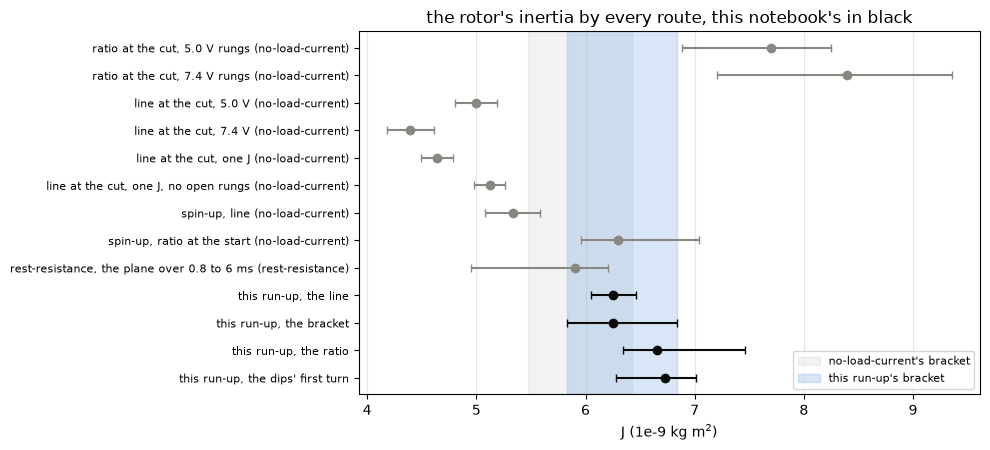

J from the run-up 6.26 x 1e-9 kg m^2, bracket 5.83 to 6.83 (16 % wide), against no-load-current's 5.47 to 6.43 (15 % wide)
one run-up's line spreads 3.3 % about the others, so the pooled line's standard error is 1.3 %, and Kt's bounds move J -0.7 to +0.4 %; current-scale's absolute class of 2 % moves J by the same share, and the bracket leaves it out


In [12]:
# the bracket on J from this run-up: the span of the line with either drag curve and the ratios under each drag, with the
# run-ups' own spread around the line, and Kt's bounds, which scale J in proportion
J_RUN = LINE["j"]
spread = PER_RUN["j"].std()                                            # one run-up's scatter about the others
se = LINE["j_se"]                                                      # the pooled line's, the spread over the root of six run-ups
kt_lo, kt_hi = NL["kt_n_m_per_a"]["lo"] / KT, NL["kt_n_m_per_a"]["hi"] / KT
J_DIPS = FIRST["j_dips"].mean()                                       # the stall end's route, from the dips
cands = [LINE["j"], LINE_HI["j"], *RATIO.values(), J_DIPS]
J_LO, J_HI = (min(cands) - se) * kt_lo, (max(cands) + se) * kt_hi
ROUTES = [(label, v["value"], v["lo"], v["hi"], "no-load-current") for label, v in NL["j_by_route"].items()]
ROUTES.append(("rest-resistance, the plane over 0.8 to 6 ms", RR["j_runup_kg_m2"]["value"], RR["j_runup_kg_m2"]["lo"], RR["j_runup_kg_m2"]["hi"], "rest-resistance"))
ROUTES.append(("this run-up, the line", J_RUN, J_RUN - spread, J_RUN + spread, "speed-torque"))
ROUTES.append(("this run-up, the bracket", J_RUN, J_LO, J_HI, "speed-torque"))
ROUTES.append(("this run-up, the ratio", RATIO["drag curve at 5.0 V"], use["j"].quantile(0.16), use["j"].quantile(0.84), "speed-torque"))
ROUTES.append(("this run-up, the dips' first turn", J_DIPS, FIRST["j_dips"].min(), FIRST["j_dips"].max(), "speed-torque"))
SRC_COLOR = {"no-load-current": MUTED, "rest-resistance": MUTED, "speed-torque": INK}
fig, ax = plt.subplots(figsize=(10, 4.6))
for y, (label, v, lo, hi, src) in enumerate(ROUTES):
    ax.errorbar(v * 1e9, y, xerr=[[(v - lo) * 1e9], [(hi - v) * 1e9]], fmt="o", color=SRC_COLOR[src], capsize=3)
ax.set_yticks(range(len(ROUTES))); ax.set_yticklabels([f"{r[0]} ({r[4]})" if r[4] != "speed-torque" else r[0] for r in ROUTES], fontsize=8); ax.invert_yaxis()
ax.axvspan(NL["j_kg_m2"]["lo"] * 1e9, NL["j_kg_m2"]["hi"] * 1e9, color=MUTED, alpha=0.10, label="no-load-current's bracket")
ax.axvspan(J_LO * 1e9, J_HI * 1e9, color=BLUE, alpha=0.18, label="this run-up's bracket")
ax.set_xlabel("J (1e-9 kg m$^2$)"); ax.set_title("the rotor's inertia by every route, this notebook's in black"); ax.legend(fontsize=8, loc="lower right"); ax.grid(alpha=0.3, axis="x")
plt.tight_layout(); plt.show()
print(f"J from the run-up {J_RUN * 1e9:.2f} x 1e-9 kg m^2, bracket {J_LO * 1e9:.2f} to {J_HI * 1e9:.2f} "
      f"({(J_HI - J_LO) / J_RUN * 100:.0f} % wide), against no-load-current's {NL['j_kg_m2']['lo'] * 1e9:.2f} to {NL['j_kg_m2']['hi'] * 1e9:.2f} "
      f"({(NL['j_kg_m2']['hi'] - NL['j_kg_m2']['lo']) / NL['j_kg_m2']['value'] * 100:.0f} % wide)")
print(f"one run-up's line spreads {spread / J_RUN * 100:.1f} % about the others, so the pooled line's standard error is {se / J_RUN * 100:.1f} %, "
      f"and Kt's bounds move J {(kt_lo - 1) * 100:+.1f} to {(kt_hi - 1) * 100:+.1f} %; current-scale's absolute class of {I_CLASS_PCT:.0f} % "
      f"moves J by the same share, and the bracket leaves it out")

The run-up puts $J$ at 6.26 x $10^{-9}$ kg m$^2$ with a bracket of 5.83 to 6.83, 16 % wide. no-load-current's routes through the coast with the reading term out read 5.47 to 6.22, and its bracket, which takes in the meter loop's R-L bias and its spin-up's ratio, runs to 6.43, so the two brackets overlap from 5.83 to 6.43. The first turn's drops, read where the current is near its stall value, land at 6.73, inside this bracket. The line sits on no-load-current's spin-up ratio, 6.30, which also reads the drive against its own settled current, and over its routes through the coast by 1 to 14 %.

The run-up reads $J$ from the drive's current less no-load-current's drag curve with the reading term out, and at 100 % no reading term is in the current either. What it assumes is that the drag during the run-up is that drag at the same speed. The line's intercept, +22 mA, says it is not. At 100 % the drive holds about 20 mA more than the partial-duty spins drew at the same speed with the term out, and the settled end shows the same, 108 and 112 mA measured against 89 and 90 mA on the curve. I report that as an observation. This notebook does not say whether it is a drag the drive at full duty has, a current the 100 % drive carries that does not turn the rotor, or the partial-duty curve reading low, and the motor-model notebook of this stage is where it gets explained. A constant difference like this moves the line's intercept and not its slope, which is why the line's $J$ holds while the ratio, which takes it as inertia, sits 6 % higher. A difference that fades through the run-up would not show in the intercept, and the low end of the bracket is what a 36 mA one would do.

So the run-up puts $J$ at about 5.8 to 6.8 x $10^{-9}$ kg m$^2$, with moderate confidence. The bracket leaves out current-scale's absolute class, 2 % of the reading, which moves $J$ one for one, and it takes $K_t = K_e$ as given. The inertia collar was not needed to pin $J$ before the teardown. The [teardown](../teardown/teardown.ipynb) weighed the rotor at 1.123 g over 7.03 mm across, and a uniform cylinder of that mass and size gives 6.9 x $10^{-9}$ kg m$^2$, a reference and not a bound, since the shaft and the commutator sit at a smaller radius and the copper and the pole tips at the rim, and a rotor of that mass and size can reach twice it. It sits just above this bracket, which a rotor with part of its mass near the shaft would give, so it checks the bracket's size and not its value. The collar stays the only route with no current in it at all that reads $J$ itself rather than a bound, so it is a test of the drag assumption the run-up and the spin-up share rather than a need.

### The terminal volts under rotation

The volts the moving rotor drops besides its EMF, $u - L \, di/dt - K_e \, \omega$, against the current, one point per turn window of the first 100 ms, with a line per direction and one through both, and the settled end of each run-up beside it at the seed's speed. Rest-resistance's terminal resistance at rest is drawn through the origin, and its read of these run-ups at 0.91 A as a square. The thing to see is whether the moving rotor's volts follow the resistance at rest, and what the line does at zero current.

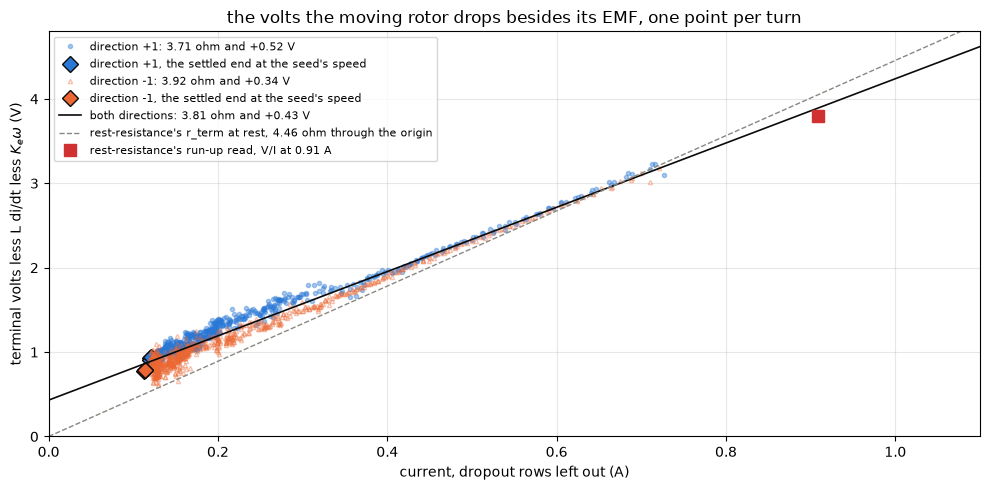

direction +1: 3.706 ohm, +0.515 V, residual 30 mV in the median, 52 mV rms, 6 of 763 windows past 5 times that left out, the settled end -38 mV off the line
direction -1: 3.917 ohm, +0.343 V, residual 38 mV in the median, 66 mV rms, 12 of 751 windows past 5 times that left out, the settled end -5 mV off the line
both: 3.808 ohm and +0.431 V, so at 0.91 A that is V/I = 4.282 ohm, rest-resistance's run-up read 4.182, its holes 4.455 at 0.78 A
over 0.8 to 6 ms u is 4.48 V, so the drop folds into R' = 4.213 ohm and J' = J x R / R' = 5.65 x 1e-9 kg m^2 before the drag, against rest-resistance's 4.182 ohm and 5.90


In [13]:
# the terminal volts under rotation: u - L di/dt - Ke w against the current over every turn window, a line per direction.
# Its slope is the resistance the moving rotor shows and its intercept a drop that stays the same as the current changes.
REV["y"] = REV["u"] - L_H * REV["didt"] - KE * REV["w"]
RU = REV[REV["t"] < SETTLED].copy()                                    # the run-up's windows, where the current sweeps
RU["line_ok"] = True
# the settled end, one point per run-up: the last 200 ms with the dropout rows left out, at the seed's speed
SET = pd.DataFrame([{"dir": r["dir"], "i": r["i"][-4000:][~r["open"][-4000:]].mean(), "u": r["u"][-4000:][~r["open"][-4000:]].mean(),
                     "w": r["w_seed"]} for r in RUNS])
SET["y"] = SET["u"] - KE * SET["w"]
VL = {}
for d in (1, -1):
    h = RU[RU["dir"] == d]
    p = np.polyfit(h["i"], h["y"], 1)
    res = h["y"] - np.polyval(p, h["i"])
    mad = np.median(np.abs(res - np.median(res)))
    keep = np.abs(res) <= 5 * mad                                       # a turn's speed jitters 1 to 2 %, about 80 mV here, and the tail is left out
    p = np.polyfit(h["i"][keep], h["y"][keep], 1)
    res = h["y"][keep] - np.polyval(p, h["i"][keep])
    RU.loc[h.index, "line_ok"] = keep
    st = SET[SET["dir"] == d]
    VL[d] = {"r": p[0], "v0": p[1], "mad": np.median(np.abs(res - np.median(res))), "rms": res.std(), "dropped": int((~keep).sum()), "n": len(h),
             "settled_off_mv": ((st["y"] - np.polyval(p, st["i"])) * 1e3).mean()}
RU["line_ok"] = RU["line_ok"].astype(bool)
p_all = np.polyfit(RU[RU["line_ok"]]["i"], RU[RU["line_ok"]]["y"], 1)
R_ROT, V0_ROT = p_all[0], p_all[1]
I_RR = RR["r_runup_amps"]["value"]                                     # the current rest-resistance read its run-up R at
fig, ax = plt.subplots(figsize=(10, 5))
for d in (1, -1):
    h = RU[RU["dir"] == d]
    ax.plot(h["i"], h["y"], MARK[d], ms=3, color=DIR_COLOR[d], mfc=DIR_COLOR[d] if d == 1 else "none", alpha=0.4,
            label=f"direction {d:+d}: {VL[d]['r']:.2f} ohm and {VL[d]['v0']:+.2f} V")
    st = SET[SET["dir"] == d]
    ax.plot(st["i"], st["y"], "D", ms=8, color=DIR_COLOR[d], mec=INK, label=f"direction {d:+d}, the settled end at the seed's speed")
x = np.linspace(0, 1.1, 10)
ax.plot(x, np.polyval(p_all, x), "-", color=INK, lw=1.2, label=f"both directions: {R_ROT:.2f} ohm and {V0_ROT:+.2f} V")
rt = RR["r_term_median_ohm"]["value"]
ax.plot(x, rt * x, "--", color=MUTED, lw=1, label=f"rest-resistance's r_term at rest, {rt:.2f} ohm through the origin")
ax.plot([I_RR], [RR["r_runup_ohm"]["value"] * I_RR], "s", ms=9, color=RED, label="rest-resistance's run-up read, V/I at 0.91 A")
ax.set_xlim(0, 1.1); ax.set_ylim(0, 4.8)
ax.set_xlabel("current, dropout rows left out (A)"); ax.set_ylabel("terminal volts less L di/dt less $K_e \\omega$ (V)")
ax.set_title("the volts the moving rotor drops besides its EMF, one point per turn"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
for d in (1, -1):
    print(f"direction {d:+d}: {VL[d]['r']:.3f} ohm, {VL[d]['v0']:+.3f} V, residual {VL[d]['mad'] * 1e3:.0f} mV in the median, {VL[d]['rms'] * 1e3:.0f} mV rms, "
          f"{VL[d]['dropped']} of {VL[d]['n']} windows past 5 times that left out, "
          f"the settled end {VL[d]['settled_off_mv']:+.0f} mV off the line")
print(f"both: {R_ROT:.3f} ohm and {V0_ROT:+.3f} V, so at {I_RR:.2f} A that is V/I = {R_ROT + V0_ROT / I_RR:.3f} ohm, "
      f"rest-resistance's run-up read {RR['r_runup_ohm']['value']:.3f}, its holes {rt:.3f} at {RR['r_term_amps']['value']:.2f} A")
# rest-resistance read the first 6 ms with no drop, i = u / R' - c Q. A drop V0 under a near-constant u folds into R' as
# R u / (u - V0), and the EMF term's c = Ke Kt / (J R) then reads J' = J R / R'
u_early = np.mean([r["u"][16:120].mean() for r in RUNS])
r_fold = R_ROT * u_early / (u_early - V0_ROT)
print(f"over 0.8 to 6 ms u is {u_early:.2f} V, so the drop folds into R' = {r_fold:.3f} ohm and J' = J x R / R' = {J_RUN * R_ROT / r_fold * 1e9:.2f} x 1e-9 kg m^2 "
      f"before the drag, against rest-resistance's {RR['r_runup_ohm']['value']:.3f} ohm and {RR['j_runup_kg_m2']['value'] * 1e9:.2f}")

They do not. The line through both directions has a slope of 3.81 ohm and an intercept of +0.43 V, 3.71 ohm and +0.52 V in direction +1 and 3.92 ohm and +0.34 V in direction -1, and the settled ends sit within 40 mV of their direction's line. A turn's speed jitters by 1 to 2 %, about 80 mV here, and the 18 windows past five times the median residual are left out of the lines. The resistance at rest through the origin, 4.455 ohm, sits under the points at low current and over them at high current. At 0.12 A, the settled end, the motor drops about 0.92 V besides its EMF in direction +1 and 0.78 V in direction -1, where 4.455 ohm accounts for 0.53 V. The line crosses the resistance at rest at about 0.67 A, and at an amp it sits 0.2 V under it.

Read as a brush drop, +0.43 V is near the top of rest-resistance's bracket of 0 to 0.5 V, with the resistance under it at 3.81 ohm, close to the 3.82 ohm that bracket's top end gives. Rest-resistance's own read of these run-ups, 4.182 ohm at 0.91 A, assumed no drop. Over its 0.8 to 6 ms the terminal volts are about 4.48 V, so a drop of 0.43 V folds into its resistance as 4.21 ohm and into its inertia as 5.65 before its drag correction of a few percent, close to the 4.182 ohm and 5.90 it read. So that read and this one agree once the drop is in, within about 1 % on the resistance.

What the intercept is stays open. A drop at the sliding brushes that does not change with the current is the plain reading. So is an EMF under drive a little lower than the coast's, which the commutation or the winding's own field would give. The intercept is about 11 % of the settled EMF, and bemf-coast's spin route read the EMF at the cut within 0.2 % of the coast's, so a lower EMF under drive would have to vanish within the first rows of the coast. Low confidence either way. The two directions differ by 0.2 V in the intercept, and the direction that drops out more reads the larger one.

### The performance curve

Speed, current, output power and efficiency against the shaft torque $J \, \alpha$, one point per acceleration fit of the first 100 ms, both directions, with the median per 0.05 mN m drawn through both. The speed panel carries the line of speed on torque per direction extrapolated to zero speed, the turn windows' $K_t \, (i - I_0)$ in gray, and the stall end read in the first milliseconds. The thing to see is the shape of each curve and where the power and the efficiency peak.

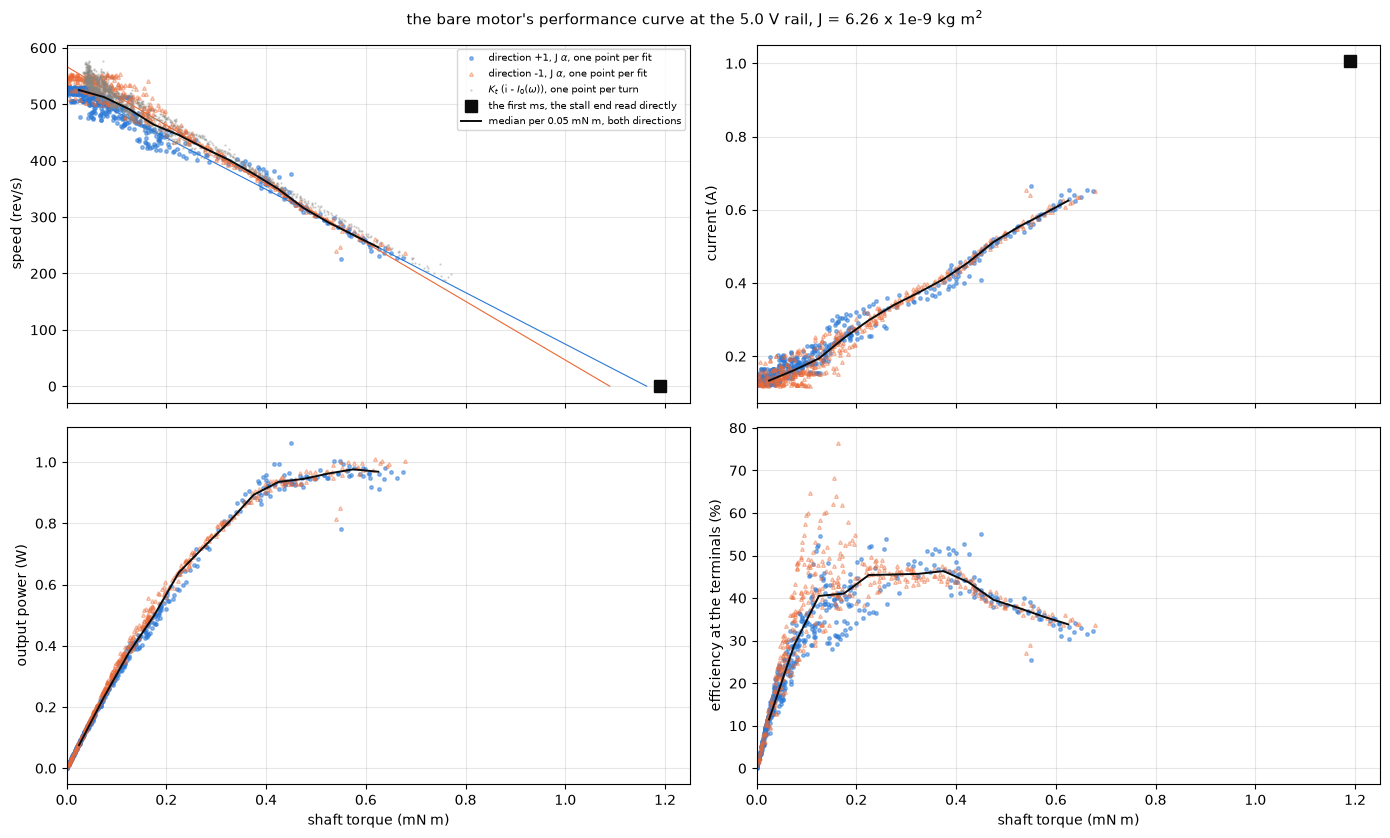

direction +1: no load 538 rev/s, stall by the line 1.163 mN m (1.195 with the speed regressed on the torque), the line at zero torque 532 rev/s, peak power 0.971 W at 0.575 mN m and 267 rev/s (the line's 0.972 W), peak efficiency 47.7 % at 0.325 mN m and 401 rev/s
direction -1: no load 557 rev/s, stall by the line 1.089 mN m (1.122 with the speed regressed on the torque), the line at zero torque 567 rev/s, peak power 0.996 W at 0.625 mN m and 253 rev/s (the line's 0.970 W), peak efficiency 45.8 % at 0.275 mN m and 424 rev/s
pooled bins: peak power 0.976 W at 0.575 mN m, peak efficiency 46.3 % at 0.375 mN m
the stall end read directly: 1.007 A at 4.43 V in the first ms, 1.190 mN m
counted range of the curve by J alpha: 226 to 553 rev/s, 0.000 to 0.679 mN m, terminal volts 4.59 to 4.87 V


In [14]:
# the performance curve. The shaft torque is J alpha, the torque the motor has left over its own drag, which here goes
# into the rotor's inertia and would go into a load. Each acceleration fit gives one point, with the speed, the current and the
# terminal volts over the same +/-5 ms. The output power is T w, the electrical power at the terminals u i, the efficiency
# their ratio. The turn windows give the torque a second way, Kt (i - I0(w)), drawn in gray, which reaches lower speeds.
C = FIT[FIT["res_ok"] & (FIT["t"] < SETTLED) & (FIT["alpha"] > 0)].copy()
C["torque"] = J_RUN * C["alpha"]
C["p_out"] = C["torque"] * C["w"]
C["p_in"] = C["u"] * C["i"]
C["eff"] = C["p_out"] / C["p_in"]
RU = REV[REV["t"] < SETTLED].copy()
RU["torque_i"] = KT * (RU["i"] - I0(RU["w"]))
STALL_I = FIRST["stall_i"].mean()                                    # the current over 0.8 to 1.5 ms, the rotor at about 30 rev/s
STALL_U = FIRST["stall_u"].mean()
W_NL = {d: np.mean([r["w_seed"] for r in RUNS if r["dir"] == d]) for d in (1, -1)}   # the settled speed, the no-load end
# a line through speed and shaft torque per direction over the counted range, extrapolated to zero speed. The torque, from the
# acceleration, is the noisy axis and the speed, from the count, the clean one, so the torque is regressed on the speed, and the
# line's zero-speed end is the stall torque
SPD = {}
for d in (1, -1):
    h = C[C["dir"] == d]
    p = np.polyfit(h["w"], h["torque"], 1)
    q_ = np.polyfit(h["torque"], h["w"], 1)                              # the other way round, speed on torque, for comparison
    SPD[d] = {"slope": 1 / p[0], "w0": -p[1] / p[0], "t_stall": p[1], "t_stall_w_on_t": -q_[1] / q_[0]}
# the stall end from the first ms: the current there with the EMF the rotor already has added back through the run-up's
# resistance, less the drag held at its lowest measured speed, through Kt
T_STALL_DIRECT = KT * (STALL_I + KE * 2 * np.pi * FIRST["w_int_1ms_rev_s"].mean() / R_ROT - I0(0))
# the curve binned by torque, both directions pooled, the medians per 0.05 mN m: this is what the result file carries
C["tbin"] = (C["torque"] * 1e3 // 0.05) * 0.05 + 0.025
BIN = C.groupby("tbin").agg(n=("w", "size"), rev_s=("rev_s", "median"), i=("i", "median"), u=("u", "median"), p_out=("p_out", "median"), eff=("eff", "median"))
BIN = BIN[BIN["n"] >= 10]
fig, ax = plt.subplots(2, 2, figsize=(14, 8.5), sharex=True)
for d in (1, -1):
    h = C[C["dir"] == d]
    kw = dict(ls="none", marker=MARK[d], ms=2.5, color=DIR_COLOR[d], mfc=DIR_COLOR[d] if d == 1 else "none", alpha=0.5, label=f"direction {d:+d}, J $\\alpha$, one point per fit")
    ax[0, 0].plot(h["torque"] * 1e3, h["rev_s"], **kw)
    ax[0, 1].plot(h["torque"] * 1e3, h["i"], **kw)
    ax[1, 0].plot(h["torque"] * 1e3, h["p_out"], **kw)
    ax[1, 1].plot(h["torque"] * 1e3, h["eff"] * 100, **kw)
    x = np.linspace(0, SPD[d]["t_stall"], 20)
    ax[0, 0].plot(x * 1e3, (SPD[d]["w0"] + SPD[d]["slope"] * x) / (2 * np.pi), "-", color=DIR_COLOR[d], lw=0.8)   # the line, extrapolated to stall
ax[0, 0].plot(RU["torque_i"] * 1e3, RU["rev_s"], ".", ms=1.5, color=MUTED, alpha=0.3, label="$K_t$ (i - $I_0(\\omega)$), one point per turn")
ax[0, 0].plot(T_STALL_DIRECT * 1e3, 0, "s", ms=9, color=INK, label="the first ms, the stall end read directly")
ax[0, 1].plot(T_STALL_DIRECT * 1e3, STALL_I, "s", ms=9, color=INK)
for a, col, sc in ((ax[0, 0], "rev_s", 1), (ax[0, 1], "i", 1), (ax[1, 0], "p_out", 1), (ax[1, 1], "eff", 100)):
    a.plot(BIN.index, BIN[col] * sc, "-", color=INK, lw=1.4, label="median per 0.05 mN m, both directions" if col == "rev_s" else None)
ax[0, 0].set_ylabel("speed (rev/s)"); ax[0, 1].set_ylabel("current (A)"); ax[1, 0].set_ylabel("output power (W)"); ax[1, 1].set_ylabel("efficiency at the terminals (%)")
ax[0, 0].legend(fontsize=7)
for a in ax.flat:
    a.grid(alpha=0.3); a.set_xlim(0, 1.25)
for a in ax[1]:
    a.set_xlabel("shaft torque (mN m)")
fig.suptitle(f"the bare motor's performance curve at the 5.0 V rail, J = {J_RUN * 1e9:.2f} x 1e-9 kg m$^2$", fontsize=11)
plt.tight_layout(); plt.show()
KEY = {}
for d in (1, -1):
    h = C[C["dir"] == d]
    b = h.groupby("tbin").agg(n=("w", "size"), p_out=("p_out", "median"), eff=("eff", "median"), rev_s=("rev_s", "median"))
    b = b[b["n"] >= 5]
    KEY[d] = {"no_load_rev_s": W_NL[d] / (2 * np.pi), "stall_line_mnm": SPD[d]["t_stall"] * 1e3,
              "p_max_w": b["p_out"].max(), "p_max_torque_mnm": b["p_out"].idxmax(), "p_max_rev_s": b.loc[b["p_out"].idxmax(), "rev_s"],
              "p_line_w": SPD[d]["t_stall"] * SPD[d]["w0"] / 4,
              "eff_max": b["eff"].max(), "eff_max_torque_mnm": b["eff"].idxmax(), "eff_max_rev_s": b.loc[b["eff"].idxmax(), "rev_s"]}
for d in (1, -1):
    k = KEY[d]
    print(f"direction {d:+d}: no load {k['no_load_rev_s']:.0f} rev/s, stall by the line {k['stall_line_mnm']:.3f} mN m "
          f"({SPD[d]['t_stall_w_on_t'] * 1e3:.3f} with the speed regressed on the torque), the line at zero torque {SPD[d]['w0'] / (2 * np.pi):.0f} rev/s, "
          f"peak power {k['p_max_w']:.3f} W at {k['p_max_torque_mnm']:.3f} mN m and {k['p_max_rev_s']:.0f} rev/s (the line's {k['p_line_w']:.3f} W), "
          f"peak efficiency {k['eff_max'] * 100:.1f} % at {k['eff_max_torque_mnm']:.3f} mN m and {k['eff_max_rev_s']:.0f} rev/s")
print(f"pooled bins: peak power {BIN['p_out'].max():.3f} W at {BIN['p_out'].idxmax():.3f} mN m, peak efficiency {BIN['eff'].max() * 100:.1f} % at {BIN['eff'].idxmax():.3f} mN m")
print(f"the stall end read directly: {STALL_I:.3f} A at {STALL_U:.2f} V in the first ms, {T_STALL_DIRECT * 1e3:.3f} mN m")
print(f"counted range of the curve by J alpha: {C['rev_s'].min():.0f} to {C['rev_s'].max():.0f} rev/s, {C['torque'].min() * 1e3:.3f} to {C['torque'].max() * 1e3:.3f} mN m, "
      f"terminal volts {C['u'].min():.2f} to {C['u'].max():.2f} V")

The speed falls along a straight line with the torque, from 538 rev/s forward and 557 rev/s reverse at no load. The torque from the acceleration is the noisy axis and the speed from the count the clean one, so the line is the torque regressed on the speed. Through the counted part, 226 to 553 rev/s and up to 0.68 mN m, it reaches zero speed at 1.16 mN m forward and 1.09 mN m reverse, 1.13 between them, and zero torque at 532 and 567 rev/s. Regressed the other way, speed on torque, it reads 1.20 and 1.12, about 3 % higher, the slope a noisy regressor pulls flat. The stall end read in the first millisecond, 1.007 A less the drag with the rotor's small EMF added back, is 1.19 mN m. So the line and the direct read sit about 5 % apart, the direct read over both directions' lines, and I put the stall torque at about 1.13 to 1.19 mN m at the 4.43 V the terminals get at an amp, moderate confidence, since the low-speed third of the curve is not counted and the direct read leans on the drag held at its lowest measured speed. The gray turn windows, the torque from the current alone, follow the same line within about 0.04 mN m, a little to its right, and reach down to 188 rev/s.

The current rises from about 0.13 A at the light end to 0.62 A at 0.63 mN m along a straight line, and on to 1.0 A at stall. The output power peaks at 0.98 W at about 0.58 mN m and 270 rev/s, half the stall torque and half the no-load speed, as a straight speed line puts it. The line's own peak, a quarter of the stall torque times the speed at zero torque, is 0.97 W. The efficiency at the terminals peaks at about 46 %, flat within a percent from 0.2 to 0.4 mN m, 450 to 375 rev/s. The two directions agree within about 7 % on every key number, direction -1 a little faster at no load and a little higher in power, and direction +1 a little higher in peak efficiency.

The curve belongs to this supply. The terminals get 4.87 V at no load and 4.43 V at stall, and the 0.5 ohm the board's path adds is part of what the motor sees. With the motor's own constants, a stiffer source of the same voltage would raise the stall torque in proportion to the volts at the terminals.

### The two readings of the shaft torque

$J \, \alpha$ against $K_t \, (i - I_0(\omega))$, every acceleration fit of the first 100 ms. The thing to see is where the two readings agree and where they part.

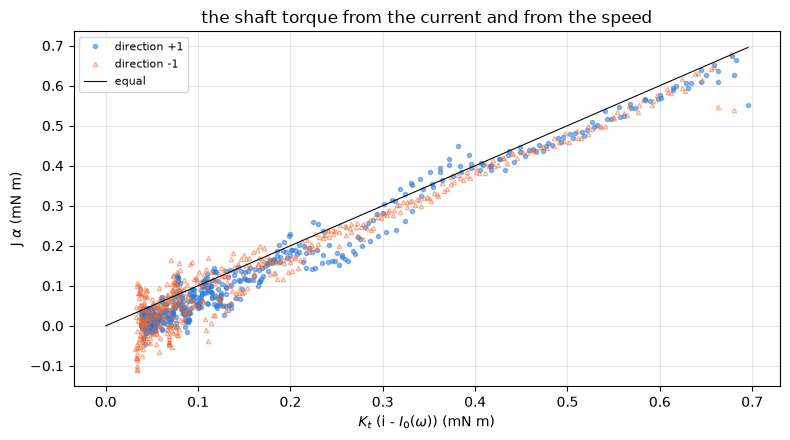

20 to 100 mA over the drag: J alpha over Kt (i - I0) 0.481 in the median, 16th to 84th percentile -0.07 to 1.06, 574 fits
100 to 300 mA over the drag: J alpha over Kt (i - I0) 0.884 in the median, 16th to 84th percentile 0.65 to 0.99, 278 fits
300 to 1000 mA over the drag: J alpha over Kt (i - I0) 0.955 in the median, 16th to 84th percentile 0.93 to 0.99, 162 fits


In [15]:
# the two readings of the shaft torque against each other: Kt (i - I0) from the current and J alpha from the speed,
# over the acceleration fits, with this notebook's J
FIT["torque_i"] = KT * FIT["ex"]
FIT["torque_w"] = J_RUN * FIT["alpha"]
both = FIT[(FIT["ex"] > 0.02) & FIT["res_ok"] & (FIT["t"] < SETTLED)]
fig, ax = plt.subplots(figsize=(8, 4.5))
for d in (1, -1):
    h = both[both["dir"] == d]
    ax.plot(h["torque_i"] * 1e3, h["torque_w"] * 1e3, MARK[d], ms=3, color=DIR_COLOR[d], mfc=DIR_COLOR[d] if d == 1 else "none", alpha=0.5, label=f"direction {d:+d}")
x = np.array([0, both["torque_i"].max() * 1e3])
ax.plot(x, x, "-", color=INK, lw=0.8, label="equal")
ax.set_xlabel("$K_t$ (i - $I_0(\\omega)$) (mN m)"); ax.set_ylabel("J $\\alpha$ (mN m)"); ax.set_title("the shaft torque from the current and from the speed")
ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()
for lo, hi in ((0.02, 0.1), (0.1, 0.3), (0.3, 1.0)):
    h = both[(both["ex"] >= lo) & (both["ex"] < hi)]
    print(f"{lo * 1e3:.0f} to {hi * 1e3:.0f} mA over the drag: J alpha over Kt (i - I0) {(h['torque_w'] / h['torque_i']).median():.3f} in the median, "
          f"16th to 84th percentile {(h['torque_w'] / h['torque_i']).quantile(0.16):.2f} to {(h['torque_w'] / h['torque_i']).quantile(0.84):.2f}, {len(h)} fits")

Above 300 mA over the drag the two agree to about 5 %, 0.955 in the median. From 100 to 300 mA the speed's torque is 0.88 of the current's, and under 100 mA, the last part of the run-up at about 500 to 550 rev/s, only about half. So about 20 mA of the current at 100 % is drag the term-out curve of the partial-duty spins does not carry, the same +22 mA the line's intercept reads and the settled end shows. No-load-current's early-run drag at 40 to 75 ms, 17 mA at 5.0 V, is about that size, and the 5.0 V curve's extrapolation above 338 rev/s, which the 7.4 V curve puts 2 to 4 mA higher, adds a little. It is also why the light end of the curve is drawn from $J \, \alpha$, the torque that actually reached the rotor, and not from the current.

The agreement above 300 mA is not a test of $K_t$. $J$ is the line through these same windows with $K_t$ taken equal to $K_e$, so $J \, \alpha$ and $K_t \, (i - I_0)$ agree there by construction, and they would agree as well for any other $K_t$ with $J$ scaled to match. $K_t = K_e$ is a fact of SI units for an ideal motor and is assumed here, not measured. The stall torque on a scale arm, in the Open questions, is a reading that would test it.

### The run-up against the model

The two equations integrated from rest, row by row, with the terminal volts as the source line above. Black, the constants as the earlier notebooks hand them, rest-resistance's terminal resistance with no drop, inductance's $L$, bemf-coast's $K_e$, no-load-current's drag and its $J$, solid at its working value and dotted and dashed at its bracket's ends. Red, the same with this notebook's resistance, drop and $J$. Left the speed, right the current. The thing to see is where the black lines leave the measured run-up and whether the red one stays on it.

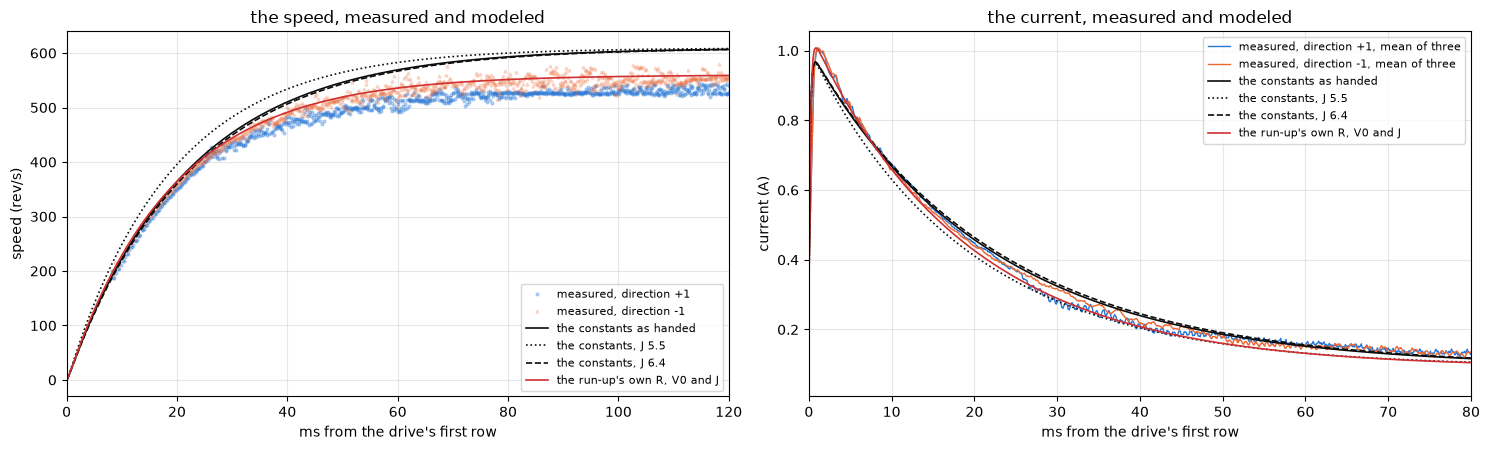

the constants as handed         : settled 609 rev/s, 63 % at 22.0 ms, current 0.958 A at 1.2 ms and 92 mA at 300 ms
the constants, J 5.5            : settled 609 rev/s, 63 % at 19.1 ms, current 0.953 A at 1.2 ms and 92 mA at 300 ms
the constants, J 6.4            : settled 609 rev/s, 63 % at 22.5 ms, current 0.959 A at 1.2 ms and 92 mA at 300 ms
the run-up's own R, V0 and J    : settled 560 rev/s, 63 % at 19.1 ms, current 1.001 A at 1.2 ms and 90 mA at 300 ms
measured, direction +1            : settled 538 rev/s, 63 % at 19.0 ms, current 1.007 A over 0.8 to 1.5 ms and 112 mA over the last 100 ms
measured, direction -1            : settled 557 rev/s, 63 % at 19.5 ms, current 1.007 A over 0.8 to 1.5 ms and 108 mA over the last 100 ms


In [16]:
def simulate(R, V0, J, n, drag=I0, src=SUP):
    # the motor from rest at 100 %, row by row: the source u = V_s - R_s i, the winding L di/dt = u - V0 - R i - Ke w, the
    # rotor J dw/dt = Kt (i - I0(w)). The drop V0 only acts while current flows, and the rotor does not turn back on its drag.
    dt = 1 / FS / 10                                                    # ten steps per row, short against L/R
    i = w = 0.0
    I, W = np.empty(n), np.empty(n)
    for k in range(n):
        for _ in range(10):
            u = np.polyval(src, i)
            di = (u - (V0 if i > 0 else 0.0) - R * i - KE * w) / L_H
            dw = KT * (i - (drag(w) if w > 0 else 0.0)) / J
            i = max(i + di * dt, 0.0); w = max(w + dw * dt, 0.0)
        I[k], W[k] = i, w
    return I, W

N_SIM = min(len(r["i"]) for r in RUNS)                              # the shortest run-up's rows
JB = NL["j_kg_m2"]
MODELS = {"the constants as handed": dict(R=RR["r_term_median_ohm"]["value"], V0=0.0, J=JB["value"]),
          f"the constants, J {JB['lo'] * 1e9:.1f}": dict(R=RR["r_term_median_ohm"]["value"], V0=0.0, J=JB["lo"]),
          f"the constants, J {JB['hi'] * 1e9:.1f}": dict(R=RR["r_term_median_ohm"]["value"], V0=0.0, J=JB["hi"]),
          "the run-up's own R, V0 and J": dict(R=R_ROT, V0=V0_ROT, J=J_RUN)}
SIM = {name: simulate(n=N_SIM, **p) for name, p in MODELS.items()}
STYLE = {list(MODELS)[0]: ("-", INK), list(MODELS)[1]: (":", INK), list(MODELS)[2]: ("--", INK), list(MODELS)[3]: ("-", RED)}
t = np.arange(N_SIM) / FS * 1e3
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
for d in (1, -1):
    h = REV[REV["dir"] == d]
    ax[0].plot(h["t"] * 1e3, h["rev_s"], MARK[d], ms=2, color=DIR_COLOR[d], mfc=DIR_COLOR[d] if d == 1 else "none", alpha=0.3, label=f"measured, direction {d:+d}")
    ii = np.mean([np.convolve(r["i"][:N_SIM], np.ones(21) / 21, mode="same") for r in RUNS if r["dir"] == d], axis=0)   # the three run-ups' mean, 1 ms boxcar
    ax[1].plot(t, ii, lw=1, color=DIR_COLOR[d], label=f"measured, direction {d:+d}, mean of three")
for name, (I, W) in SIM.items():
    ls, c = STYLE[name]
    ax[0].plot(t, W / (2 * np.pi), ls, color=c, lw=1.2, label=name)
    ax[1].plot(t, I, ls, color=c, lw=1.2, label=name)
ax[0].set_ylabel("speed (rev/s)"); ax[1].set_ylabel("current (A)"); ax[1].set_xlim(0, 80); ax[0].set_xlim(0, 120)
for a in ax:
    a.set_xlabel("ms from the drive's first row"); a.grid(alpha=0.3); a.legend(fontsize=8)
ax[0].set_title("the speed, measured and modeled"); ax[1].set_title("the current, measured and modeled")
plt.tight_layout(); plt.show()

def rise_ms(w, frac=0.632):
    # the time the speed takes to reach a share of its value at 300 ms
    return float(np.flatnonzero(w >= frac * w[-1])[0] / FS * 1e3)
MEAS_RISE = {}
for d in (1, -1):
    h = REV[REV["dir"] == d].sort_values("t")
    wm = h.groupby((h["t"] * 2000).round())["w"].median()              # the three run-ups' median per half ms
    wm.index = wm.index / 2000
    MEAS_RISE[d] = float(wm.index[np.flatnonzero(wm.values >= 0.632 * W_NL[d])[0]] * 1e3)
for name, (I, W) in SIM.items():
    print(f"{name:32s}: settled {W[-1] / (2 * np.pi):.0f} rev/s, 63 % at {rise_ms(W):.1f} ms, current {I[int(0.0012 * FS)]:.3f} A at 1.2 ms and {I[-1] * 1e3:.0f} mA at 300 ms")
for d in (1, -1):
    print(f"measured, direction {d:+d}            : settled {W_NL[d] / (2 * np.pi):.0f} rev/s, 63 % at {MEAS_RISE[d]:.1f} ms, current "
          f"{FIRST[FIRST['dir'] == d]['stall_i'].mean():.3f} A over 0.8 to 1.5 ms and {np.mean([r['i'][-2000:].mean() for r in RUNS if r['dir'] == d]) * 1e3:.0f} mA over the last 100 ms")

With the constants as handed, the model settles at 609 rev/s, 9 % over direction -1 and 13 % over direction +1, and draws 0.96 A at 1.2 ms against the measured 1.007 A. Both come from the resistance, 4.455 ohm with no drop, which takes too little of the volts at the light end and a little too much at the stall end, as the line above showed. Its rise to 63 % of the settled speed takes 22.0 ms, against 19.0 and 19.5 ms measured, and no-load-current's bracket on $J$, 5.5 to 6.4, spreads that from 19.1 to 22.5 ms. With this notebook's resistance, drop and $J$ the model reaches 63 % at 19.1 ms and draws 1.001 A at 1.2 ms, on the measured run-up through its start and its rise. So the stage's constants draw the run-up's start and rise once the resistance carries its drop, with moderate confidence.

The settled end is another matter. The model settles at 560 rev/s, over both directions, 538 and 557 rev/s, and draws 90 mA at 300 ms against 112 and 108 mA measured. That is the drag again. The model takes the term-out drag of the partial-duty spins, and at 100 % the drive draws about 20 mA more at the same speed, which slows the measured rotor and raises its current. I report that as an observation for the motor-model notebook of this stage. no-load-current's drag as the board reads it at partial duty, with the reading term in, sits 15 to 23 mA over the term-out curve, about the same amount, so a model drawn with that curve would land on the settled end by trading one effect for the other.

### The coast from full speed

The coast after each run-up starts at about 540 rev/s, above bemf-coast's fastest cycles. The EMF over the whole ripple cycles closest to 10 ms from 1 ms past the cut, over the speed the same cycles count, as bemf-coast reads $K_e$, with the open rows bridged as it does and as read beside it. The model and the terminal-volts line above take $K_e$ at this speed from bemf-coast's mean, so this checks it there.

In [17]:
# the coast from full speed: the EMF over the whole ripple cycles closest to 10 ms from 1 ms past the cut, over the speed the
# same cycles count, as bemf-coast reads it, with the rest difference as the zero and the open rows bridged. The rotor slows through the window, and
# the mean EMF over the mean speed of the same rows is Ke as long as Ke holds over the window.
def bridge_open(e, start=20, nbh=41, frac=0.3, turn=0.05):
    # bemf-coast's open rows, an EMF row under 30 % of the mean of the 2 ms around it while the rotor turns, bridged by a line
    ref = np.convolve(e, np.ones(nbh) / nbh, mode="same")
    bad = (e < frac * ref) & (ref > turn)
    bad[:start] = False
    out = e.copy()
    x = np.arange(len(e))
    out[bad] = np.interp(x[bad], x[~bad], e[~bad])
    return out, int(bad[:start + int(0.012 * FS)].sum())

def coast_ke(r, start=20, target_ms=10):
    e, n_open = bridge_open(r["e_coast"])
    f = r["f_coast"]
    for _ in range(6):
        n = int(round(target_ms / 1e3 * f))
        stop = start + int((n + 3) * FS / f * 1.3)
        sos = butter(2, [f * 0.65, min(f * 1.35, 0.95 * FS / 2)], btype="band", fs=FS, output="sos")
        y = sosfiltfilt(sos, e[start:stop] - e[start:stop].mean())
        s = np.flatnonzero((y[:-1] < 0) & (y[1:] >= 0))
        tc = (s + (-y[s]) / (y[s + 1] - y[s]))[1:-1][:n + 1]
        f_new = n / ((tc[-1] - tc[0]) / FS)
        done = abs(f_new / f - 1) < 1e-4
        f = f_new
        if done:
            break
    i0, i1 = start + int(np.ceil(tc[0])), start + int(np.floor(tc[-1]))
    w = 2 * np.pi * f / N_R
    return {"k": r["k"], "dir": r["dir"], "rev_s": w / (2 * np.pi), "emf_v": e[i0:i1].mean(), "ke": e[i0:i1].mean() / w,
            "ke_read": r["e_coast"][i0:i1].mean() / w, "open_rows": n_open,
            "cut_over_settled_pct": (w / r["w_seed"] - 1) * 100}
CK = pd.DataFrame([coast_ke(r) for r in RUNS])
CK["ke_mv"], CK["ke_read_mv"] = CK["ke"] * 1e3, CK["ke_read"] * 1e3            # mV s/rad, so the table shows the digits
show(CK[["k", "dir", "rev_s", "emf_v", "ke_mv", "ke_read_mv", "open_rows", "cut_over_settled_pct"]], n=None)
print(f"Ke over the coast's first window at {CK['rev_s'].min():.0f} to {CK['rev_s'].max():.0f} rev/s: {CK['ke'].mean() * 1e3:.4f} mV s/rad "
      f"(sd {CK['ke'].std() / CK['ke'].mean() * 100:.2f} %), {(CK['ke'].mean() / KE - 1) * 100:+.2f} % from bemf-coast's {KE * 1e3:.4f}, "
      f"whose own windows reach {BC['speed_range_rev_s']['hi']:.0f} rev/s")
print("per direction: " + ", ".join(f"{d:+d} {CK[CK['dir'] == d]['ke'].mean() * 1e3:.4f}" for d in (1, -1))
      + f", as read {CK['ke_read'].mean() * 1e3:.4f}, {int(CK['open_rows'].sum())} open rows bridged in the coasts' first 13 ms")
print(f"bemf-coast's own fastest cycles, 60 % at 7.4 V, as read: " + ", ".join(f"{k} {v['value'] * 1e3:.4f}" for k, v in BC["ke_read_by_direction_top"].items())
      + f", and its trend under the rest zero {BC['ke_speed_trend_pct_per_100_rev_s']['value']:+.2f} % per 100 rev/s")

,k,dir,rev_s,emf_v,ke_mv,ke_read_mv,open_rows,cut_over_settled_pct
0,0,1,523.982,3.820,1.160,1.140,4,-2.477
1,0,-1,541.138,3.928,1.155,1.139,4,-3.116
2,1,1,523.721,3.820,1.161,1.145,3,-3.052
3,1,-1,536.014,3.921,1.164,1.155,2,-3.692
4,2,1,521.324,3.816,1.165,1.143,4,-2.670
5,2,-1,537.114,3.906,1.158,1.154,1,-3.494


Ke over the coast's first window at 521 to 541 rev/s: 1.1606 mV s/rad (sd 0.32 %), -0.67 % from bemf-coast's 1.1684, whose own windows reach 491 rev/s
per direction: +1 1.1621, -1 1.1590, as read 1.1459, 18 open rows bridged in the coasts' first 13 ms
bemf-coast's own fastest cycles, 60 % at 7.4 V, as read: +1 1.1434, -1 1.1550, and its trend under the rest zero -0.26 % per 100 rev/s


$K_e$ reads 1.1606 mV s/rad at 521 to 541 rev/s, with a spread of 0.32 % over the six coasts, 0.67 % under bemf-coast's mean. bemf-coast's windows fell 0.26 % per 100 rev/s under the same zero, to about -0.6 % at 450 rev/s, so this point sits close to where that trend runs on to. The two directions agree within 0.3 %. Left as read, with the 18 open rows in, the read is 1.1459, 1.9 % low, like bemf-coast's fastest cycles as read. So $K_e$ holds to within 0.7 % at the top of the curve, and at the settled EMF of about 3.9 V that is under 30 mV, under a tenth of the intercept above.

### The results file

$J$ with its bracket, the line and its per-direction values and the ratios under each drag. The moving rotor's resistance and drop. The key numbers of the curve, pooled and per direction, the curve itself in torque bins, the terminal source line, where the count starts, the count's repairs, the dropouts, the model's settled speeds and rise times against the measured ones, and $K_e$ at the top speed.

In [18]:
q = results.quantity

def spread(x, unit, scale=1.0):
    # mean with the sd as the bounds
    x = pd.Series(x).dropna() * scale
    return q(x.mean(), x.mean() - x.std(), x.mean() + x.std(), unit)

curve = [{"torque_mnm": round(float(b), 3), "n": int(r.n), "speed_rev_s": round(float(r.rev_s), 2), "current_a": round(float(r.i), 5),
          "terminal_v": round(float(r.u), 4), "power_w": round(float(r.p_out), 5), "efficiency": round(float(r.eff), 4)} for b, r in BIN.iterrows()]
path = results.write("2-motor", "speed-torque", CAPTURE, pair=MOTOR.key,
    notes="the free motor from rest at 100 % on the 5.0 V rail, three cycles of a 300 ms run-up and a 600 ms coast each way. The speed is the "
          "commutation ripple of the current counted at 6 events per revolution, by order tracking: the current resampled onto a rough angle and "
          "band-passed there at six per revolution +/- 25 %, the rough angle seeded by the coast's ripple line and refined from the count, "
          "missed and extra crossings repaired; speed per one-turn window, acceleration from a quadratic of angle on time over +/-5 ms. "
          "Current through current-scale with its in-drive offset, graded at 100 %, terminal volts through terminal-chain. The shaft torque is "
          "J alpha, and Kt (i - I0(w)) beside it, with I0 no-load-current's 5.0 V drag curve under drive with the reading term out (drive_drag_by_level_meter), "
          "since a 100 % run-up carries no reading term, held at its lowest speed's value below its range and "
          "extrapolated above it; Kt is taken equal to Ke and not tested; j_kg_m2 is the slope of the acceleration on that torque over the windows 150 mA and more over the drag, its "
          "bounds the span of the line with the 5.0 and 7.4 V curves, the ratio with either curve and with 17 and 36 mA of early-run drag, and the first turn's "
          "commutation dips read against the current's integral (j_dips_first_turn_kg_m2), widened by the "
          "standard error over the six run-ups and Kt's bounds, and leaving out current-scale's 2 % absolute class, which moves J one for one; "
          "j_line_kg_m2's bounds are +/- the six run-ups' spread over the root of six, since the fits overlap. "
          "r_rotating_ohm and v0_rotating_v are the line of u - L di/dt - Ke w on the current over the turn windows of the first 100 ms, dropout rows left out. "
          "The curve's key numbers are per direction and pooled, the stall torque from the line of the torque on the speed, the torque being the noisy axis, at zero speed "
          "and from the first ms beside it, the peaks the largest median per 0.05 mN m bin of the acceleration fits, pooled, with the two directions' as bounds; "
          "curve is those bins, the shaft torque J alpha with this notebook's J",
    j_kg_m2=q(J_RUN, J_LO, J_HI, "kg m^2"),
    j_line_kg_m2=q(LINE["j"], LINE["j"] - LINE["j_se"], LINE["j"] + LINE["j_se"], "kg m^2"),
    j_line_by_direction={f"{d:+d}": spread(PER_RUN[PER_RUN["dir"] == d]["j"], "kg m^2") for d in (1, -1)},
    j_line_drag_7v4_kg_m2=q(LINE_HI["j"], unit="kg m^2"),
    j_ratio_by_drag={k: q(v, unit="kg m^2") for k, v in RATIO.items()},
    j_line_extra_drag_a=q(LINE["extra_a"], unit="A"),
    j_dips_first_turn_kg_m2=q(J_DIPS, FIRST["j_dips"].min(), FIRST["j_dips"].max(), "kg m^2"),
    j_windows=q(len(use), use["t"].min(), use["t"].max(), "windows, from lo to hi s into the run-up"),
    r_rotating_ohm=q(R_ROT, min(VL[1]["r"], VL[-1]["r"]), max(VL[1]["r"], VL[-1]["r"]), "ohm"),
    v0_rotating_v=q(V0_ROT, min(VL[1]["v0"], VL[-1]["v0"]), max(VL[1]["v0"], VL[-1]["v0"]), "V"),
    no_load_speed_rev_s=q(np.mean(list(W_NL.values())) / (2 * np.pi), min(W_NL.values()) / (2 * np.pi), max(W_NL.values()) / (2 * np.pi), "rev/s"),
    no_load_speed_by_direction={f"{d:+d}": q(W_NL[d] / (2 * np.pi), unit="rev/s") for d in (1, -1)},
    no_load_current_a=spread([r["i"][-2000:].mean() for r in RUNS], "A"),
    stall_torque_n_m=q(np.mean([SPD[d]["t_stall"] for d in (1, -1)]), min(SPD[d]["t_stall"] for d in (1, -1)), max(SPD[d]["t_stall"] for d in (1, -1)), "N m"),
    stall_torque_first_ms_n_m=q(T_STALL_DIRECT, unit="N m"),
    stall_current_a=spread(FIRST["stall_i"], "A"),
    stall_terminal_v=spread(FIRST["stall_u"], "V"),
    peak_power_w=q(BIN["p_out"].max(), min(KEY[d]["p_max_w"] for d in (1, -1)), max(KEY[d]["p_max_w"] for d in (1, -1)), "W"),
    peak_power_torque_n_m=q(BIN["p_out"].idxmax() * 1e-3, unit="N m"),
    peak_efficiency=q(BIN["eff"].max(), min(KEY[d]["eff_max"] for d in (1, -1)), max(KEY[d]["eff_max"] for d in (1, -1)), ""),
    peak_efficiency_torque_n_m=q(BIN["eff"].idxmax() * 1e-3, unit="N m"),
    key_numbers_by_direction={f"{d:+d}": {k: float(v) for k, v in KEY[d].items()} for d in (1, -1)},
    terminal_source={"form": "u = v_s - r_s i at the motor's terminals, the rail, the diode, the bridge and the leads as one source",
                     "v_s": q(SUP[1], unit="V"), "r_s": q(-SUP[0], unit="ohm")},
    speed_count_start_ms=q(FIRST["first_window_ms"].mean(), FIRST["first_window_ms"].min(), FIRST["first_window_ms"].max(), "ms"),
    speed_count_start_rev_s=q(FIRST["first_rev_s"].mean(), FIRST["first_rev_s"].min(), FIRST["first_rev_s"].max(), "rev/s"),
    crossings_repaired=q(int(CNT["added"].sum() + CNT["removed"].sum()), unit="count"),
    crossings_total=q(int(CNT["crossings"].sum()), unit="count"),
    dropouts_settled_per_s_by_direction={f"{d:+d}": spread(Q[Q["dir"] == d]["open_late_per_s"], "1/s") for d in (1, -1)},
    model_settled_rev_s={name: q(W[-1] / (2 * np.pi), unit="rev/s") for name, (I, W) in SIM.items()},
    model_rise_63_ms={name: q(rise_ms(W), unit="ms") for name, (I, W) in SIM.items()},
    measured_rise_63_ms={f"{d:+d}": q(MEAS_RISE[d], unit="ms") for d in (1, -1)},
    ke_coast_top_v_s_per_rad=spread(CK["ke"], "V s/rad"),
    ke_coast_top_rev_s=spread(CK["rev_s"], "rev/s"),
    curve=curve)
print("wrote", path, "with", len(curve), "torque bins in the curve")

wrote stages/2-motor/speed-torque/results/mg90-b.json with 13 torque bins in the curve


## Limitations

- The speed has no outside ruler. It is the ripple counted at six events per revolution, a parts count, as in every notebook of this stage. A wrong count would scale every speed by one factor and $J$ by its square, through $K_t$ and the acceleration together.
- $K_t = K_e$ is assumed and not tested. $J$ is read with it, so the agreement of the two torque readings over the windows $J$ is fitted on says nothing about it, and every torque here scales with $K_t$.
- Every current goes through current-scale's counts per amp, whose absolute class is 2 % of the reading, the DMM's class on the 20 A jack it was graded against. $J$ scales one for one with that scale, and its bracket leaves it out.
- The curve's low-speed third, from rest to about 200 rev/s and from about 0.7 mN m to the stall end, is not counted. The commutation drops read its speed from 85 rev/s, and it is drawn between the first counted fit and the stall end read in the first millisecond, with the current's integral as the check, so its shape there is assumed straight.
- The speed still creeps up about 2 % from 100 to 300 ms, so the no-load speeds, the means over the last 200 ms, are a percent or so under where a longer spin would settle.
- The drag under drive is no-load-current's settled curve at 5.0 V with the reading term out, from partial-duty spins, extrapolated above 338 rev/s and held flat under 64 rev/s. The drag at rest, which sets the stall end, is that held value and not a measured static friction. At 100 % the drive draws about 20 mA more than that curve at the same speed, in the line's intercept, in the last part of the run-up and at the settled end, and the model leaves it out.
- The settled current, about 0.11 A, is under current-scale's graded range of 0.23 to 1.31 A, and the dropout rows are about 5 % of the settled rows. Both enter the light end of the curve and the terminal-volts line's intercept.
- The brushes' drop and the moving rotor's resistance come from a line over 0.11 to 0.9 A of a moving rotor. A drop at the brushes and an EMF a little lower under drive are not told apart.
- One rail, one motor, three cycles, the motor's first few minutes of running at 100 %. no-load-current found its coast drag falling about 2 % over its first half hour.

## Open questions

- Whether the drag during a run-up is the settled drag at the same speed. The run-up and no-load-current's spin-up both assume it, and at 100 % the drive draws about 20 mA more than the partial-duty curve with the reading term out, at the settled end as well as in the run-up. Steady spins at 100 % from rails of 3 to 5 V, with a meter in series, put the 100 % no-load current against the partial-duty curve at the same speeds, and say whether the 20 mA follows the duty or the speed. A collar of known inertia clamped on the pinion, with coasts from the same speeds with and without it, reads $J$ with no current at all, as $J = J_c \, \alpha_c / (\alpha - \alpha_c)$, and with the run-up's $J$ beside it says how much of the run-up's current is drag. The same run-ups with the collar on, at a higher $J$ and so a slower run-up, put more drag time into the same speeds and split a drag that fades with time from one that follows speed.
- What the 0.43 V intercept of the moving rotor's volts is. A drop at the brushes predicts the same intercept at any speed for the same current. An EMF under drive lower than the coast's predicts an intercept that grows with the speed. Steady spins at 100 % on rails from 3.7 to 7.4 V, read at their settled ends with the coast that follows each, put the settled current and speed at several points and split the two. A scope with a differential probe across the terminals at the cut shows whether the EMF steps between the last driven row and the first coasting one.
- Why direction +1 drops a larger drop, +0.52 V against +0.34 V, and drops out twice as often at full speed. Swapping the motor's leads at the board's connector and running the cycles again sorts the motor from the board, as bemf-coast suggests for its own direction split. The [teardown](../teardown/teardown.ipynb) did not settle how each brush meets the commutator, and did not observe brush bounce.
- What the stall end is at zero speed, and whether $K_t = K_e$. A locked lap at 100 % on the 5.0 V rail with the bar on reads the stall current at the same terminal volts with no EMF at all, and the stall torque with the bar on a scale arm reads it with no constant in between, so the two together give $K_t$ against bemf-coast's $K_e$.
- What the curve is at other rails. The same cycles at 3.7, 4.2 and 7.4 V draw the curve at each, and the stall torques over the terminal volts check that the curve scales the way the constants say.

## Conclusion

Started from rest at 100 % on a 5.0 V rail, the bare mg90-b motor runs up to 538 rev/s forward and 557 rev/s reverse, within 5 % of that by about 58 ms, drawing about an amp at the start and 0.11 A at the end, with its terminals at 4.43 and 4.87 V. Against the shaft torque, its speed falls along a straight line to a stall torque of about 1.13 mN m by the line through the counted part, the torque regressed on the speed, and 1.19 mN m read directly from the first millisecond, about 5 % apart. The output power peaks at 0.98 W at about 0.58 mN m and 270 rev/s, and the efficiency at the terminals at about 46 %, flat from 0.2 to 0.4 mN m. The two directions agree within about 7 % on every key number. The ripple count reads the curve from about 200 rev/s up. Below that the commutation drops in the current read the speed from 85 rev/s, the first millisecond's current reads the stall end, and the current's integral, which meets the drops and the count within about 6 %, joins them.

The run-up puts the rotor's inertia at 6.26 +/- 0.08 x $10^{-9}$ kg m$^2$, with a bracket of 5.8 to 6.8, against no-load-current's 5.5 to 6.4 with the reading term out, and the first turn's commutation drops read 6.7 at the stall end. It reads $J$ from the drive's current at 100 %, which carries no reading term, against no-load-current's drag with the term out, and I hold that with moderate confidence. Both rest on $K_t = K_e$, which this notebook does not test, and on current-scale's scale, whose 2 % class moves $J$ one for one. An inertia collar was not needed to pin $J$ before the teardown. The [teardown](../teardown/teardown.ipynb)'s rotor, 1.123 g over 7.03 mm across, gives 6.9 x $10^{-9}$ kg m$^2$ as a uniform cylinder, a reference and not a bound, just over the bracket, which checks its size and not its value. The collar remains the one route that reads $J$ itself free of the drag assumption this one and the spin-up share.

At 100 % the drive draws about 20 mA more than the partial-duty drag at the same speed, 108 and 112 mA at the settled end against 89 and 90 mA on no-load-current's term-out curve, and the line's intercept reads the same +22 mA through the run-up. That is an observation here, and the motor-model notebook of this stage is where it gets explained. The moving rotor drops 3.81 ohm and +0.43 V besides its EMF, near the top of rest-resistance's brush-drop bracket, and with that the model drawn from the stage's constants follows the measured run-up's start and rise, 1.001 A at 1.2 ms and 63 % of its speed at 19.1 ms against 19.0 and 19.5 ms. It settles at 560 rev/s against 538 and 557 and draws 90 mA at the end, the 20 mA it leaves out. With the resistance at rest and no drop the model runs 9 to 13 % too fast. Rest-resistance's own read of these run-ups agrees with this once the drop is in.

Later stages take `j_kg_m2` as the rotor's inertia with its bracket, the curve from `curve` with the stall torque and the no-load speed as its ends, and `r_rotating_ohm` with `v0_rotating_v` for a model of the moving motor in place of the resistance at rest. Stage 3 draws the same curve through the gear train and grades it against this one.